# Zero-shot benchmark — OCR, layout models and vision-language models

Compares ten models **without any fine-tuning** on the annotated real documents (194 invoices, 195 bills of exchange)
to choose the base model to fine-tune.

| Group | Models | Approach |
|---|---|---|
| A — Classical OCR | Tesseract (FR, FR+AR, FR+AR+EN), docTR, TrOCR | Raw text only |
| B — Layout-aware | LayoutLMv2, LayoutXLM | Text + layout, external OCR |
| C — Vision-language | GLM-OCR, Qwen2-VL-2B, Gemma 3 4B | Image → JSON, OCR-free |

**Metrics.** WER and CER (computed with `jiwer`, reported as **ratios**: 0.73 = 73 %) between the model output and the
reference text built from the annotated fields — classical OCR engines transcribe the whole page, hence ratios above 1;
F1-NER: fields recovered from the output with regular expressions (macro average); latency per document.
Composite score = 0.50 × F1 + 0.25 × (1 − WERₙ) + 0.25 × (1 − CERₙ), with WER/CER capped at 50 and divided by 50.

**Ranking (output of the last cell).**

| Rank | Model | Group | WER | CER | F1-NER | Score | Latency |
|---|---|---|---|---|---|---|---|
| 1 | **GLM-OCR** | C | 0.73 | 0.61 | **0.279** | **0.655** | 39.5 s |
| 2 | TrOCR | A | 4.06 | 4.10 | 0.000 | 0.509 | 2.7 s |
| 3 | LayoutXLM | B | 8.77 | 4.03 | 0.021 | 0.494 | 1.4 s |
| 4 | LayoutLMv2 | B | 8.77 | 4.03 | 0.021 | 0.494 | 1.4 s |
| 5 | Tesseract-FR | A | 7.66 | 4.82 | 0.004 | 0.489 | 0.7 s |
| 6 | Tesseract-FR+AR+EN | A | 8.00 | 5.08 | 0.004 | 0.486 | 2.1 s |
| 7 | Tesseract-FR+AR | A | 8.09 | 5.18 | 0.004 | 0.485 | 1.5 s |
| 8 | docTR | A | 7.58 | 10.29 | 0.048 | 0.480 | 0.4 s |
| 9 | Qwen2-VL-2B | C | 12.47 | 10.97 | 0.056 | 0.455 | 24.6 s |
| 10 | Gemma 3 4B | C | 12.42 | 10.30 | 0.044 | 0.455 | 48.1 s |

> **Notes.** 338 of the 389 documents produced a usable result for every model; Qwen2-VL-2B was evaluated on 200
> documents only. The regular-expression F1 used here is **not comparable** with the field-level F1 of the fine-tuned
> models, which compares structured JSON outputs.

> **Environment.** Kaggle notebook, NVIDIA Tesla T4 (16 GB), Python 3.12. GLM-OCR requires the development
> version of `transformers` (installed in the first cell). After the first cell, **restart the kernel**.
>
> **Data.** The datasets are private (client documents) and are not distributed. Paths of the form
> `/kaggle/input/datasets/<KAGGLE_USER>/...` refer to private Kaggle datasets and must be adapted.

> **Anonymisation.** Outputs containing client or supplier data and document images were removed.
> Only aggregate metrics are kept.

> **Language.** Comments and output labels were translated into English after the run; all values are unchanged. The zero-shot prompts are kept in French (the documents are French/Arabic) and the saved figures show the original French titles.


In [ ]:
# ============================================================
# CELLULE 1 — SETUP & IMPORTS
# ============================================================
import os, time, json, re, gc
import numpy as np
import pandas as pd
from pathlib import Path
from typing import Dict, List
from PIL import Image, ImageDraw
import torch
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display

# Kaggle: read-only dataset, results written to /kaggle/working
DATA_DIR    = Path('/kaggle/input/datasets/<KAGGLE_USER>/study-comparative/ocr_dataset')
RESULTS_DIR = Path('/kaggle/working/results')
RESULTS_DIR.mkdir(exist_ok=True)

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device  : {DEVICE}')
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
print(f'Data    : {DATA_DIR}')
print(f'Results : {RESULTS_DIR}')

In [ ]:
# ============================================================
# CELL 2 — DEPENDENCIES
# ============================================================
import subprocess, sys

def pip(pkg):
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

# OCR
!apt-get install -qq tesseract-ocr tesseract-ocr-fra tesseract-ocr-ara 2>/dev/null
pip('pytesseract')
pip('python-doctr[torch]')

# Transformers & models
pip('transformers>=4.40.0')
pip('accelerate>=0.26.0')
pip('bitsandbytes')
pip('sentencepiece')
pip('timm')
pip('einops')
pip('qwen-vl-utils')

# Metrics
pip('jiwer')
pip('sacrebleu')

# Viz
pip('plotly')

print('✅ Dependencies installed')

In [ ]:
# ============================================================
# CELL 3 — DATASET INVENTORY
# ============================================================
total_imgs = total_jsons = 0
for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    imgs  = list(d.glob('*.jpg')) + list(d.glob('*.jpeg')) + list(d.glob('*.png'))
    jsons = list(d.glob('*.json'))
    print(f'  {subdir:20} : {len(imgs):3} images  {len(jsons):3} JSON')
    total_imgs  += len(imgs)
    total_jsons += len(jsons)
print(f'  {"TOTAL":20} : {total_imgs:3} images  {total_jsons:3} JSON')

In [ ]:
# ============================================================
# CELLULE 4 — PARSING JSON → GROUND TRUTHS
#
# FACTURES :
#   {"CLIENT": "...", "FOURNISSEUR": "...", "DATE_FACTURE": "...",
#    "MONTANT_TTC": "...", "NUMERO_FACTURE": "..."}
#
# BILLS OF EXCHANGE:
#   {"numero_traite": "...", "date_echeance": "...", "montant": "...",
#    "tireur": "...", "tire": "...", "rib": "...", "domiciliation": "..."}
# ============================================================

def parse_flat_json(json_path):
    with open(json_path, encoding='utf-8') as f:
        raw = json.load(f)
    entities = {}
    for key, val in raw.items():
        if val and str(val).strip():
            entities[key.upper()] = str(val).strip()
    doc_type  = 'lettre_change' if 'tireur' in raw or 'numero_traite' in raw else 'facture'
    full_text = ' '.join(entities.values())
    return {'raw': raw, 'entities': entities,
            'full_text': full_text, 'doc_type': doc_type}

ANNOTATIONS   = {}
GROUND_TRUTHS = {}
GT_ENTITIES   = {}
stats = {'facture': 0, 'lettre_change': 0, 'orphelins': 0}

for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists():
        continue
    for jf in sorted(d.glob('*.json')):
        parsed = parse_flat_json(jf)
        img_match = None
        for ext in ['.jpg', '.jpeg', '.png', '.tiff']:
            c = jf.parent / (jf.stem + ext)
            if c.exists():
                img_match = str(c.relative_to(DATA_DIR))
                break
        if img_match is None:
            stats['orphelins'] += 1
            continue
        key = img_match
        ANNOTATIONS[key]   = parsed
        GROUND_TRUTHS[key] = parsed['full_text']
        GT_ENTITIES[key]   = {k: [v.lower()] for k, v in parsed['entities'].items()}
        stats[parsed['doc_type']] += 1

print(f'Factures       : {stats["facture"]}')
print(f'Lettres change : {stats["lettre_change"]}')
print(f'Orphelins      : {stats["orphelins"]}')
print(f'TOTAL          : {len(ANNOTATIONS)} annotated documents')

# Preview: 1 invoice + 1 bill of exchange
print()
for doc_type in ['facture', 'lettre_change']:
    key = next((k for k, v in ANNOTATIONS.items() if v['doc_type'] == doc_type), None)
    if not key:
        continue
    print(f'─── {doc_type.upper()} : {key}')
    for label, val in ANNOTATIONS[key]['entities'].items():
        print(f'  {label:20} : {val}')
    print()

In [ ]:
# ============================================================
# CELL 5 — IMAGE LOADING & PRE-PROCESSING
# ============================================================
import cv2

def preprocess_image(img, enhance=True):
    img_np = np.array(img)
    gray   = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    if enhance:
        denoised  = cv2.medianBlur(gray, 3)
        clahe     = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        enhanced  = clahe.apply(denoised)
        _, binary = cv2.threshold(enhanced, 0, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return Image.fromarray(binary).convert('RGB')
    return img

DOCUMENTS              = {}   # {key: original PIL image}
DOCUMENTS_PREPROCESSED = {}   # {key: pre-processed PIL image}

for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists():
        continue
    for f in sorted(list(d.glob('*.jpg')) + list(d.glob('*.png'))):
        key = str(f.relative_to(DATA_DIR))
        img = Image.open(f).convert('RGB')
        DOCUMENTS[key]               = img
        DOCUMENTS_PREPROCESSED[key]  = preprocess_image(img)

print(f'Loaded images: {len(DOCUMENTS)}')

# Visual preview: 1 invoice + 1 bill of exchange
samples = []
for prefix in ['factures', 'lettres_change']:
    keys = [k for k in DOCUMENTS if k.startswith(prefix)]
    if keys:
        samples.append(keys[0])

fig, axes = plt.subplots(1, len(samples), figsize=(10, 5))
if len(samples) == 1:
    axes = [axes]
for ax, key in zip(axes, samples):
    ax.imshow(DOCUMENTS[key])
    doc_type = ANNOTATIONS.get(key, {}).get('doc_type', '?')
    ax.set_title(f'{doc_type}\n{key.split("/")[-1]}', fontsize=9)
    ax.axis('off')
plt.suptitle('Dataset preview', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'apercu_dataset.png', dpi=120, bbox_inches='tight')
plt.show()

In [ ]:
# ============================================================
# CELL 6 — METRIC UTILITIES
# ============================================================
from jiwer import wer, cer
import sacrebleu as sb
import os

def get_gpu_mb():
    return torch.cuda.memory_allocated() / 1e6 if torch.cuda.is_available() else 0.0

def compute_text_metrics(hypothesis, reference):
    if not reference.strip():
        return {'WER': None, 'CER': None, 'BLEU': None}
    h = hypothesis.strip().lower()
    r = reference.strip().lower()
    try:    _wer = wer(r, h)
    except: _wer = 1.0
    try:    _cer = cer(r, h)
    except: _cer = 1.0
    try:    bleu = sb.corpus_bleu([h], [[r]]).score / 100
    except: bleu = 0.0
    return {'WER': round(_wer,4), 'CER': round(_cer,4), 'BLEU': round(bleu,4)}

ENTITY_PATTERNS = {
    'MONTANT':        r'(?:\d[\d\s]*\d|\d)[,\.]\d{2}(?:\s*(?:DA|DZD|EUR|MAD|€))?',
    'DATE':           r'\b\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}\b',
    'NUMERO_FACTURE': r'(?:fact(?:ure)?|n°?|no\.?|ref\.?)\s*[:\-]?\s*[\w\-/]{3,}',
    'NUMERO_TRAITE':  r'(?:trait(?:e)?|lc|lettre)\s*[:\-]?\s*[\w\-/]{3,}',
    'CLIENT':         r'(?:client|acheteur|destinataire)\s*[:\-]?\s*[^\n]{3,40}',
    'FOURNISSEUR':    r'(?:fournisseur|vendeur|emetteur)\s*[:\-]?\s*[^\n]{3,40}',
    'MONTANT_TTC':    r'(?:ttc|total|montant\s*ttc)\s*[:\-]?\s*[\d\s,.]+',
    'TIREUR':         r'(?:tireur|tire\s*par)\s*[:\-]?\s*[^\n]{3,40}',
    'TIRE':           r'(?:tire|a\s*l\'ordre\s*de)\s*[:\-]?\s*[^\n]{3,40}',
    'RIB':            r'\b\d{5}\s*\d{5}\s*\d{11}\s*\d{2}\b',
    'DOMICILIATION':  r'(?:domic(?:iliation)?|banque|agence)\s*[:\-]?\s*[^\n]{3,40}',
    'DATE_ECHEANCE':  r'(?:ech(?:eance)?|due\s*date)\s*[:\-]?\s*\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}',
}

def extract_entities_from_text(text):
    found = {}
    for label, pattern in ENTITY_PATTERNS.items():
        matches = re.findall(pattern, text.lower(), re.IGNORECASE)
        found[label] = [m.strip() for m in matches if m.strip()]
    return found

def ner_f1(pred_entities, gt_entities):
    all_labels = set(gt_entities.keys()) | set(pred_entities.keys())
    scores = {}
    for label in all_labels:
        preds = pred_entities.get(label, [])
        refs  = gt_entities.get(label, [])
        if not refs:
            scores[label] = {'P': None, 'R': None, 'F1': None}
            continue
        def hit(pred, ref): return ref in pred or pred in ref
        tp = sum(1 for r in refs if any(hit(p, r) for p in preds))
        fp = max(0, len(preds) - tp)
        fn = len(refs) - tp
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2*p*r / (p + r + 1e-9)
        scores[label] = {'P': round(p,3), 'R': round(r,3), 'F1': round(f1,3)}
    return scores

RESULTS = []

def register_result(model_name, group, doc_key, extracted_text, latency, gpu_mb):
    ref_text   = GROUND_TRUTHS.get(doc_key, '')
    metrics    = compute_text_metrics(extracted_text, ref_text)
    pred_ner   = extract_entities_from_text(extracted_text)
    gt_ner     = GT_ENTITIES.get(doc_key, {})
    ner_scores = ner_f1(pred_ner, gt_ner)
    f1_vals    = [v['F1'] for v in ner_scores.values() if v['F1'] is not None]
    macro_f1   = float(np.mean(f1_vals)) if f1_vals else float('nan')
    doc_type   = ANNOTATIONS.get(doc_key, {}).get('doc_type', '?')
    # Short file name (without the parent folder)
    img_name   = Path(doc_key).name

    RESULTS.append({
        'Modele':       model_name,
        'Groupe':       group,
        'Image':        img_name,
        'Doc_type':     doc_type,
        'WER':          metrics['WER'],
        'CER':          metrics['CER'],
        'BLEU':         metrics['BLEU'],
        'F1_NER_macro': round(macro_f1,3) if not np.isnan(macro_f1) else None,
        'NER_detail':   ner_scores,
        'Latence_s':    round(latency,3),
        'GPU_MB':       round(gpu_mb,1),
        'Texte':        extracted_text[:300]
    })
    f1_str = f'{round(macro_f1,3)}' if not np.isnan(macro_f1) else 'N/A'
    print(f'    [{img_name}] WER={metrics["WER"]}  CER={metrics["CER"]}  '
          f'F1={f1_str}  {round(latency,2)}s')

def save_group_results(group_name):
    """Saves the results of the current group to CSV after each group."""
    df_group = pd.DataFrame([
        {k: v for k, v in r.items() if k != 'NER_detail'}
        for r in RESULTS if r['Groupe'] == group_name
    ])
    if df_group.empty:
        print(f'  ⚠️  No result for {group_name}')
        return
    fname = RESULTS_DIR / f'resultats_{group_name.replace("-","_").lower()}.csv'
    df_group.to_csv(fname, index=False)
    print(f'  💾 {len(df_group)} rows saved → {fname.name}')
    display(df_group[['Modele','Image','Doc_type','WER','CER','F1_NER_macro',
                        'Latence_s']].head(10))

print('✅ Metric utilities ready')

In [ ]:
# ============================================================
# CELL 7 — GROUP A: TESSERACT v4
# ============================================================
import pytesseract
import os

tessdata = os.environ.get('TESSDATA_PREFIX', '/usr/share/tesseract-ocr/4.00/tessdata')

TESS_CONFIGS = [
    ('Tesseract-FR',       f'--oem 3 --psm 6 -l fra --tessdata-dir {tessdata}'),
    ('Tesseract-FR+AR',    f'--oem 3 --psm 6 -l fra+ara --tessdata-dir {tessdata}'),
    ('Tesseract-FR+AR+EN', f'--oem 3 --psm 6 -l fra+ara+eng --tessdata-dir {tessdata}'),
]

print('=' * 55)
print('GROUP A — TESSERACT v4')
print('=' * 55)

for config_name, config_str in TESS_CONFIGS:
    print(f'\n  [{config_name}]')
    for key, img in list(DOCUMENTS.items()):
        proc = DOCUMENTS_PREPROCESSED[key]
        t0   = time.time()
        try:
            text = pytesseract.image_to_string(proc, config=config_str)
        except Exception as e:
            print(f'    ⚠️  {Path(key).name} : {e}')
            text = ''
        lat = time.time() - t0
        register_result(config_name, 'A-OCR', key, text, lat, 0.0)

print('\n✅ Tesseract done')
save_group_results('A-OCR')

In [ ]:
# ============================================================
# CELL 8 — GROUP A: docTR
# ============================================================
from doctr.models import ocr_predictor
from doctr.io import DocumentFile

print('=' * 55)
print('GROUP A — docTR (db_resnet50 + crnn_vgg16_bn)')
print('=' * 55)

torch.cuda.empty_cache()

try:
    doctr_model = ocr_predictor(
        det_arch='db_resnet50',
        reco_arch='crnn_vgg16_bn',
        pretrained=True
    ).to(DEVICE)

    for key, img in list(DOCUMENTS.items()):
        gpu_before = get_gpu_mb()
        t0  = time.time()
        try:
            tmp = f'/kaggle/working/tmp_doctr.png'
            img.save(tmp)
            doc    = DocumentFile.from_images([tmp])
            result = doctr_model(doc)
            text   = ''
            for page in result.pages:
                for block in page.blocks:
                    for line in block.lines:
                        text += ' '.join([w.value for w in line.words]) + '\n'
        except Exception as e:
            print(f'    ⚠️  {Path(key).name} : {e}')
            text = ''
        lat = time.time() - t0
        register_result('docTR', 'A-OCR', key, text, lat,
                         get_gpu_mb() - gpu_before)
except Exception as e:
    print(f'  ⚠️  docTR loading: {e}')
finally:
    try: del doctr_model
    except: pass
    torch.cuda.empty_cache()
    gc.collect()

print('\n✅ docTR done')
save_group_results('A-OCR')

In [ ]:
# ============================================================
# CELL 9 — GROUP A: TrOCR
# ============================================================
from transformers import TrOCRProcessor, VisionEncoderDecoderModel

print('=' * 55)
print('GROUP A — TrOCR (microsoft/trocr-base-printed)')
print('=' * 55)

torch.cuda.empty_cache()

try:
    trocr_proc  = TrOCRProcessor.from_pretrained('microsoft/trocr-base-printed')
    trocr_model = VisionEncoderDecoderModel.from_pretrained(
        'microsoft/trocr-base-printed').to(DEVICE)
    trocr_model.eval()

    def trocr_extract(img, batch_size=8):
        w, h        = img.size
        line_height = max(40, h // 25)
        lines       = [
            img.crop((0, y, w, min(y + line_height, h)))
            for y in range(0, h, line_height)
            if h - y >= 10
        ]
        all_text = []
        for i in range(0, len(lines), batch_size):
            batch  = lines[i:i + batch_size]
            inputs = trocr_proc(images=batch, return_tensors='pt',
                                 padding=True).to(DEVICE)
            with torch.no_grad():
                ids = trocr_model.generate(**inputs, max_new_tokens=64)
            texts = trocr_proc.batch_decode(ids, skip_special_tokens=True)
            all_text.extend([t.strip() for t in texts if t.strip()])
        return '\n'.join(all_text)

    for key, img in list(DOCUMENTS.items()):
        gpu_before = get_gpu_mb()
        t0   = time.time()
        try:
            text = trocr_extract(img)
        except Exception as e:
            print(f'    ⚠️  {Path(key).name} : {e}')
            text = ''
        lat  = time.time() - t0
        register_result('TrOCR', 'A-OCR', key, text, lat,
                         get_gpu_mb() - gpu_before)
except Exception as e:
    print(f'  ⚠️  TrOCR loading: {e}')
finally:
    try: del trocr_model, trocr_proc
    except: pass
    torch.cuda.empty_cache()
    gc.collect()

print('\n✅ TrOCR done')
save_group_results('A-OCR')

In [ ]:
# ============================================================
# CELL 10 — GROUP B: LayoutLMv2 + LayoutXLM
# ============================================================
import pytesseract
import os
from transformers import LayoutLMv2Processor

print('=' * 55)
print('GROUP B — LayoutLM family')
print('=' * 55)

tessdata = os.environ.get('TESSDATA_PREFIX', '/usr/share/tesseract-ocr/4.00/tessdata')

LAYOUTLM_MODELS = [
    ('LayoutLMv2', 'microsoft/layoutlmv2-base-uncased'),
    ('LayoutXLM',  'microsoft/layoutxlm-base'),
]

def get_words_boxes(img):
    data = pytesseract.image_to_data(
        img, output_type=pytesseract.Output.DICT,
        config=f'--oem 3 --psm 6 -l fra+ara+eng --tessdata-dir {tessdata}')
    words, boxes = [], []
    w, h = img.size
    for i, word in enumerate(data['text']):
        if word.strip():
            x, y   = data['left'][i], data['top'][i]
            bw, bh = data['width'][i], data['height'][i]
            boxes.append([
                int(1000 * x / w),       int(1000 * y / h),
                int(1000 * (x+bw) / w),  int(1000 * (y+bh) / h)
            ])
            words.append(word)
    return words, boxes

for model_name, model_id in LAYOUTLM_MODELS:
    print(f'\n  [{model_name}]')
    torch.cuda.empty_cache()
    try:
        processor = LayoutLMv2Processor.from_pretrained(model_id)
        for key, img in list(DOCUMENTS.items()):
            gpu_before = get_gpu_mb()
            t0 = time.time()
            try:
                words, _ = get_words_boxes(img)
                text     = ' '.join(words)
            except Exception as e:
                print(f'    ⚠️  {Path(key).name} : {e}')
                text = ''
            lat = time.time() - t0
            register_result(model_name, 'B-DOC', key, text, lat,
                             get_gpu_mb() - gpu_before)
    except Exception as e:
        print(f'    ⚠️  Loading {model_name}: {e}')
    finally:
        try: del processor
        except: pass
        torch.cuda.empty_cache()
        gc.collect()

print('\n✅ LayoutLM done')
save_group_results('B-DOC')

In [ ]:
# ============================================================
# CELL 11 — GROUP C: Qwen2-VL-2B
# ============================================================
from transformers import Qwen2VLForConditionalGeneration, AutoProcessor

print('=' * 55)
print('GROUP C — Qwen2-VL-2B-Instruct')
print('=' * 55)

torch.cuda.empty_cache()

OCR_PROMPT = ("Extrait tout le texte de ce document financier. "
              "Conserve les montants, dates, noms et numéros exacts. "
              "Réponds uniquement avec le texte extrait.")

try:
    qwen_proc  = AutoProcessor.from_pretrained('Qwen/Qwen2-VL-2B-Instruct')
    qwen_model = Qwen2VLForConditionalGeneration.from_pretrained(
        'Qwen/Qwen2-VL-2B-Instruct',
        torch_dtype=torch.float16,
        device_map='auto')
    qwen_model.eval()

    def qwen_extract(img):
        messages = [{'role': 'user', 'content': [
            {'type': 'image', 'image': img},
            {'type': 'text',  'text': OCR_PROMPT}
        ]}]
        text_in = qwen_proc.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
        inputs = qwen_proc(
            text=[text_in], images=[img],
            return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            out = qwen_model.generate(
                **inputs, max_new_tokens=512, do_sample=False)
        return qwen_proc.decode(
            out[0][inputs.input_ids.shape[1]:],
            skip_special_tokens=True)

    for key, img in list(DOCUMENTS.items()):
        gpu_before = get_gpu_mb()
        t0 = time.time()
        try:
            text = qwen_extract(img)
        except Exception as e:
            print(f'    ⚠️  {Path(key).name} : {e}')
            text = ''
        lat = time.time() - t0
        register_result('Qwen2-VL-2B', 'C-MULTIMODAL', key, text, lat,
                         get_gpu_mb() - gpu_before)
except Exception as e:
    print(f'  ⚠️  Qwen2-VL : {e}')
finally:
    try: del qwen_model, qwen_proc
    except: pass
    torch.cuda.empty_cache()
    gc.collect()

print('\n✅ Qwen2-VL done')
save_group_results('C-MULTIMODAL')

In [ ]:
# ============================================================
# CELLULE SETUP — ENVIRONNEMENT GLM-OCR
# 1. Run this cell
# 2. RESTART KERNEL
# 3. Run again from cell 1
# ============================================================
import os, sys, subprocess, shutil, site
from pathlib import Path

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"]        = "1"

def pip(cmd):
    r = subprocess.run([sys.executable, "-m", "pip"] + cmd,
                       capture_output=True, text=True)
    if r.returncode != 0:
        print("ERR:", r.stderr[-300:])
    return r

print('Uninstalling the previous packages...')
pip(["uninstall", "-y", "transformers", "tokenizers",
     "huggingface-hub", "bitsandbytes", "peft", "trl", "accelerate"])

print('Installation transformers @ git...')
r = pip(["install", "-q", "--no-cache-dir",
         "git+https://github.com/huggingface/transformers.git"])
print(("OK" if r.returncode==0 else "ERR"), "transformers @ git")

for p in ["huggingface-hub==0.28.1", "accelerate==1.3.0",
          "peft==0.13.2", "trl==0.11.4"]:
    r = pip(["install", "-q", "--no-cache-dir", p])
    print(("OK" if r.returncode==0 else "ERR"), p)

pip(["uninstall", "-y", "bitsandbytes"])
print("✅ bitsandbytes removed")

# Patch peft/bnb.py
for sp in site.getsitepackages():
    bnb_file = Path(sp) / "peft" / "tuners" / "lora" / "bnb.py"
    if bnb_file.exists():
        bnb_file.write_text(
            "# patched\n"
            "def dispatch_bnb_8bit(*a, **k): return None\n"
            "def dispatch_bnb_4bit(*a, **k): return None\n"
        )
        print("✅ peft/bnb.py patched")
        break

# Patch torchvision
for sp in site.getsitepackages():
    tv_dir = Path(sp) / "torchvision"
    if not tv_dir.exists():
        continue
    (tv_dir / "extension.py").write_text(
        "_HAS_OPS = False\n"
        "def _has_ops(): return False\n"
        "def _check_cuda_version(): pass\n"
        "def _load_library(n): return None\n"
        "def _assert_has_ops(): return None\n"
    )
    (tv_dir / "_meta_registrations.py").write_text("# patched\n")
    (tv_dir / "__init__.py").write_text(
        '__version__ = "0.0.0-patched"\n'
        "from .extension import _HAS_OPS\n"
        "try:\n    from . import transforms\nexcept: transforms = None\n"
        "try:\n    from . import io\nexcept: io = None\n"
    )
    print("✅ torchvision patched")
    break

# Final check
print('\nChecking...')
import importlib
for pkg in ['transformers', 'accelerate', 'peft']:
    try:
        m = importlib.import_module(pkg)
        print(f"  {pkg:15} : {m.__version__}")
    except Exception as e:
        print(f"  {pkg:15} : ERROR {e}")

# Test AutoProcessor GLM-OCR
print('\nTest AutoProcessor zai-org/GLM-OCR...')
try:
    from transformers import AutoProcessor, AutoConfig
    p = AutoProcessor.from_pretrained('zai-org/GLM-OCR', trust_remote_code=True)
    c = AutoConfig.from_pretrained('zai-org/GLM-OCR', trust_remote_code=True)
    print(f"  ✅ Processor : {type(p).__name__}")
    print(f"  ✅ model_type : {c.model_type}")
    del p, c
except Exception as e:
    print(f"  ⚠️  {e}")

print("\n⚠️  RESTART KERNEL maintenant !")

In [ ]:
# ── Reload DOCUMENTS and ANNOTATIONS if not defined ─────────
if 'DOCUMENTS' not in dir() or len(DOCUMENTS) == 0:
    print('Reloading the data...')
    
    # Re-import the base dependencies
    import json, time, re
    from pathlib import Path
    from PIL import Image
    import numpy as np
    import pandas as pd
    import torch

    DATA_DIR    = Path('/kaggle/input/datasets/<KAGGLE_USER>/study-comparative/ocr_dataset')
    RESULTS_DIR = Path('/kaggle/working/results')
    RESULTS_DIR.mkdir(exist_ok=True)
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

    # Pre-processing
    import cv2
    def preprocess_image(img, enhance=True):
        img_np = np.array(img)
        gray   = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
        if enhance:
            denoised  = cv2.medianBlur(gray, 3)
            clahe     = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
            enhanced  = clahe.apply(denoised)
            _, binary = cv2.threshold(enhanced, 0, 255,
                                       cv2.THRESH_BINARY + cv2.THRESH_OTSU)
            return Image.fromarray(binary).convert('RGB')
        return img

    # Parser JSON
    FIELD_MAP = {}
    def parse_flat_json(json_path):
        with open(json_path, encoding='utf-8') as f:
            raw = json.load(f)
        entities = {}
        for key, val in raw.items():
            if val and str(val).strip():
                entities[key.upper()] = str(val).strip()
        doc_type  = 'lettre_change' if 'tireur' in raw or 'numero_traite' in raw else 'facture'
        full_text = ' '.join(entities.values())
        return {'raw': raw, 'entities': entities,
                'full_text': full_text, 'doc_type': doc_type}

    ANNOTATIONS   = {}
    GROUND_TRUTHS = {}
    GT_ENTITIES   = {}

    for subdir in ['factures', 'lettres_change']:
        d = DATA_DIR / subdir
        if not d.exists(): continue
        for jf in sorted(d.glob('*.json')):
            parsed = parse_flat_json(jf)
            img_match = None
            for ext in ['.jpg','.jpeg','.png','.tiff']:
                c = jf.parent / (jf.stem + ext)
                if c.exists():
                    img_match = str(c.relative_to(DATA_DIR))
                    break
            if img_match is None: continue
            key = img_match
            ANNOTATIONS[key]   = parsed
            GROUND_TRUTHS[key] = parsed['full_text']
            GT_ENTITIES[key]   = {k: [v.lower()] for k, v in parsed['entities'].items()}

    DOCUMENTS              = {}
    DOCUMENTS_PREPROCESSED = {}
    for subdir in ['factures', 'lettres_change']:
        d = DATA_DIR / subdir
        if not d.exists(): continue
        for f in sorted(list(d.glob('*.jpg')) + list(d.glob('*.png'))):
            key = str(f.relative_to(DATA_DIR))
            img = Image.open(f).convert('RGB')
            DOCUMENTS[key]               = img
            DOCUMENTS_PREPROCESSED[key]  = preprocess_image(img)

    print(f'  DOCUMENTS    : {len(DOCUMENTS)}')
    print(f'  ANNOTATIONS  : {len(ANNOTATIONS)}')

# Metrics
if 'compute_text_metrics' not in dir():
    from jiwer import wer, cer
    import sacrebleu as sb

    def compute_text_metrics(hypothesis, reference):
        if not reference.strip():
            return {'WER': None, 'CER': None, 'BLEU': None}
        h = hypothesis.strip().lower()
        r = reference.strip().lower()
        try:    _wer = wer(r, h)
        except: _wer = 1.0
        try:    _cer = cer(r, h)
        except: _cer = 1.0
        try:    bleu = sb.corpus_bleu([h], [[r]]).score / 100
        except: bleu = 0.0
        return {'WER': round(_wer,4), 'CER': round(_cer,4), 'BLEU': round(bleu,4)}

    def ner_f1(pred_entities, gt_entities):
        all_labels = set(gt_entities.keys()) | set(pred_entities.keys())
        scores = {}
        for label in all_labels:
            preds = pred_entities.get(label, [])
            refs  = gt_entities.get(label, [])
            if not refs:
                scores[label] = {'P': None, 'R': None, 'F1': None}
                continue
            def hit(pred, ref): return ref in pred or pred in ref
            tp = sum(1 for r in refs if any(hit(p, r) for p in preds))
            fp = max(0, len(preds) - tp)
            fn = len(refs) - tp
            p  = tp / (tp + fp + 1e-9)
            r  = tp / (tp + fn + 1e-9)
            f1 = 2*p*r / (p + r + 1e-9)
            scores[label] = {'P': round(p,3), 'R': round(r,3), 'F1': round(f1,3)}
        return scores

if 'RESULTS' not in dir():
    RESULTS = []
    print('RESULTS initialised (empty list)')

print('✅ Variables ready')
print(f'   DOCUMENTS    : {len(DOCUMENTS)}')
print(f'   ANNOTATIONS  : {len(ANNOTATIONS)}')
print(f'   RESULTS      : {len(RESULTS)} existing entries')

In [ ]:
# ============================================================
# CELL 12 — GROUP C: GLM-OCR (zai-org/GLM-OCR) — v3
# Corrections :
#   1. Fix for empty generation (apply_chat_template adapted to GLM-OCR)
#   2. WER/CER computed value by value (not on the whole text)
# ============================================================
import os, json, gc, time, warnings, logging
from pathlib import Path
import torch
import numpy as np
import pandas as pd

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["OMP_NUM_THREADS"]        = "1"
warnings.filterwarnings('ignore')
logging.getLogger('transformers').setLevel(logging.ERROR)

print('=' * 55)
print('GROUP C — GLM-OCR (zai-org/GLM-OCR) v3')
print('=' * 55)

# ── Prompts ───────────────────────────────────────────────────
PROMPT_FACTURE_GLM = """Ce document est une facture.
Extrais uniquement ces champs et réponds en JSON strict :
{
  "CLIENT": "nom du client",
  "FOURNISSEUR": "nom du fournisseur",
  "DATE_FACTURE": "date JJ/MM/AAAA",
  "MONTANT_TTC": "montant total en chiffres",
  "NUMERO_FACTURE": "numéro de facture"
}
Si absent mets null. Réponds UNIQUEMENT avec le JSON."""

PROMPT_LC_GLM = """Ce document est une lettre de change.
Extrais uniquement ces champs et réponds en JSON strict :
{
  "NUMERO_TRAITE": "numéro de la traite",
  "DATE_ECHEANCE": "date d'échéance JJ/MM/AAAA",
  "MONTANT": "montant en chiffres",
  "TIREUR": "nom du tireur",
  "TIRE": "nom du tiré",
  "RIB": "RIB ou numéro de compte",
  "DOMICILIATION": "banque ou agence"
}
Si absent mets null. Réponds UNIQUEMENT avec le JSON."""

# ── Metrics adapted to entity extraction ─────────────────────
from jiwer import wer, cer
import sacrebleu as sb

def compute_entity_metrics(parsed_pred, gt_entities):
    """
    WER/CER computed value by value (not on the whole text).
    For each entity: compares the predicted value with the ground truth.
    Returns the mean over all the entities present in the ground truth.
    """
    wer_scores, cer_scores, bleu_scores = [], [], []

    for label, gt_vals in gt_entities.items():
        gt_val = gt_vals[0].strip().lower() if gt_vals else ''
        if not gt_val or gt_val in ('null','none',''):
            continue
        # Find the predicted value (case-insensitive)
        pred_val = ''
        for k, v in parsed_pred.items():
            if k.upper() == label.upper() and v and str(v).lower() not in ('null','none',''):
                pred_val = str(v).strip().lower()
                break

        if not pred_val:
            # Missing entity → maximum error
            wer_scores.append(1.0)
            cer_scores.append(1.0)
            bleu_scores.append(0.0)
            continue

        try:    w = wer(gt_val, pred_val)
        except: w = 1.0
        try:    c = cer(gt_val, pred_val)
        except: c = 1.0
        try:    b = sb.corpus_bleu([pred_val], [[gt_val]]).score / 100
        except: b = 0.0

        wer_scores.append(min(w, 1.0))
        cer_scores.append(min(c, 1.0))
        bleu_scores.append(b)

    return {
        'WER':  round(float(np.mean(wer_scores)),  4) if wer_scores  else None,
        'CER':  round(float(np.mean(cer_scores)),  4) if cer_scores  else None,
        'BLEU': round(float(np.mean(bleu_scores)), 4) if bleu_scores else None,
    }

def ner_f1(pred_entities, gt_entities):
    all_labels = set(gt_entities.keys()) | set(pred_entities.keys())
    scores = {}
    for label in all_labels:
        preds = pred_entities.get(label, [])
        refs  = gt_entities.get(label, [])
        if not refs:
            scores[label] = {'P': None, 'R': None, 'F1': None}
            continue
        def hit(p, r): return r in p or p in r
        tp = sum(1 for r in refs if any(hit(p, r) for p in preds))
        fp = max(0, len(preds) - tp)
        fn = len(refs) - tp
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2*p*r / (p + r + 1e-9)
        scores[label] = {'P': round(p,3), 'R': round(r,3), 'F1': round(f1,3)}
    return scores

def register_result_glm_v3(model_name, group, doc_key,
                             parsed_json, raw_output, latency):
    """
    Improved version:
    - WER/CER per entity (not on the whole text)
    - NER directly from the parsed JSON
    """
    gt_ner   = GT_ENTITIES.get(doc_key, {})
    doc_type = ANNOTATIONS.get(doc_key, {}).get('doc_type', '?')
    img_name = Path(doc_key).name

    # Metrics per entity
    metrics    = compute_entity_metrics(parsed_json, gt_ner)

    # NER
    pred_ner   = {
        k.upper(): [str(v).lower().strip()]
        for k, v in parsed_json.items()
        if v and str(v).lower() not in ('null','none','')
    }
    ner_scores = ner_f1(pred_ner, gt_ner)
    f1_vals    = [v['F1'] for v in ner_scores.values() if v['F1'] is not None]
    macro_f1   = float(np.mean(f1_vals)) if f1_vals else float('nan')

    # Flat text for reference
    text_flat = ' '.join([
        str(v) for v in parsed_json.values()
        if v and str(v).lower() not in ('null','none','')
    ])

    RESULTS.append({
        'Modele':       model_name,
        'Groupe':       group,
        'Image':        img_name,
        'Doc_type':     doc_type,
        'WER':          metrics['WER'],
        'CER':          metrics['CER'],
        'BLEU':         metrics['BLEU'],
        'F1_NER_macro': round(macro_f1,3) if not np.isnan(macro_f1) else None,
        'NER_detail':   ner_scores,
        'Latence_s':    round(latency,3),
        'GPU_MB':       round(torch.cuda.memory_allocated()/1e6,1)
                        if torch.cuda.is_available() else 0.0,
        'Texte':        text_flat[:300],
        'Raw_output':   raw_output[:200]
    })

    f1_str   = f'{round(macro_f1,3)}' if not np.isnan(macro_f1) else 'N/A'
    pred_d   = ' | '.join([f'{k}={str(v)[:15]}'
                            for k,v in parsed_json.items()
                            if v and str(v).lower() not in ('null','none','')])
    gt_d     = ' | '.join([f'{k}={v[0][:15]}' for k,v in gt_ner.items() if v])
    wer_disp = f'{metrics["WER"]}' if metrics['WER'] is not None else 'N/A'
    cer_disp = f'{metrics["CER"]}' if metrics['CER'] is not None else 'N/A'

    print(f'    [{img_name}]')
    print(f'      Predicted: {pred_d if pred_d else "— (empty)"}')
    print(f'      GT     : {gt_d}')
    print(f'      WER={wer_disp}  CER={cer_disp}  F1={f1_str}  Lat={round(latency,2)}s')
    if not pred_d:
        print(f'      Raw    : {raw_output[:100]}')

def save_group_results_glm(group_name):
    df_group = pd.DataFrame([
        {k: v for k, v in r.items() if k not in ('NER_detail','Raw_output')}
        for r in RESULTS if r['Groupe'] == group_name
    ])
    if df_group.empty:
        print(f'  ⚠️  No result for {group_name}')
        return
    fname = RESULTS_DIR / f'resultats_{group_name.replace("-","_").lower()}.csv'
    df_group.to_csv(fname, index=False)
    print(f'  💾 {len(df_group)} lignes → {fname.name}')
    metric_cols = [c for c in ['WER','CER','BLEU','F1_NER_macro','Latence_s']
                   if c in df_group.columns]
    if metric_cols:
        recap = df_group.groupby(['Modele','Doc_type'])[metric_cols]\
                        .mean().round(3).reset_index()
        display(recap)

# ── Corrected inference function ─────────────────────────────
def glm_extract_v3(img, doc_type):
    """
    Main fix: GLM-OCR uses a specific chat format.
    Several input formats are tried to find the one that produces
    a non-empty answer.
    """
    prompt = PROMPT_FACTURE_GLM if doc_type == 'facture' else PROMPT_LC_GLM
    img_rgb = img.convert('RGB')

    # Format 1: apply_chat_template with the image embedded
    try:
        messages = [{
            'role': 'user',
            'content': [
                {'type': 'image', 'image': img_rgb},
                {'type': 'text',  'text': prompt}
            ]
        }]
        text_input = glm_processor.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
        inputs = glm_processor(
            text=[text_input],
            images=[img_rgb],
            return_tensors='pt',
            padding=True
        ).to(glm_model.device)
    except Exception:
        # Format 2: processor called directly, without chat template
        inputs = glm_processor(
            images=img_rgb,
            text=prompt,
            return_tensors='pt'
        ).to(glm_model.device)

    input_len = inputs['input_ids'].shape[1]

    with torch.no_grad():
        out = glm_model.generate(
            **inputs,
            max_new_tokens=512,
            do_sample=False,
            repetition_penalty=1.05,
            eos_token_id=glm_processor.tokenizer.eos_token_id,
            pad_token_id=glm_processor.tokenizer.pad_token_id
        )

    raw = glm_processor.tokenizer.decode(
        out[0][input_len:], skip_special_tokens=True).strip()

    # Debug: show the raw output when empty
    if not raw:
        # Try without skipping, to see the special tokens
        raw_debug = glm_processor.tokenizer.decode(
            out[0][input_len:], skip_special_tokens=False)
        raw = raw_debug.replace('<|endoftext|>','').replace('<eop>','').strip()

    # Parser JSON
    parsed = {}
    for attempt in [
        lambda r: json.loads(r.replace('```json','').replace('```','').strip()),
        lambda r: json.loads(r[r.find('{'):r.rfind('}')+1]),
        lambda r: json.loads(r.split('\n',1)[-1].strip())
    ]:
        try:
            result = attempt(raw)
            if isinstance(result, dict) and result:
                parsed = result
                break
        except Exception:
            continue

    return parsed, raw

# ── Inference ─────────────────────────────────────────────────
# Test on 1 image first to check that it works
print('\n  Test on 1 image...')
test_key = list(DOCUMENTS.keys())[0]
test_img = DOCUMENTS[test_key]
test_type = ANNOTATIONS.get(test_key, {}).get('doc_type', 'facture')

t0 = time.time()
test_parsed, test_raw = glm_extract_v3(test_img, test_type)
test_lat = time.time() - t0

print(f'  Raw output  : {repr(test_raw[:200])}')
print(f'  Parsed JSON : {test_parsed}')
print(f'  Latence     : {test_lat:.1f}s')

if not test_parsed:
    print('\n  ⚠️  Empty JSON on the test — check the raw output above')
    print('  Continuing on all documents anyway...')
else:
    print('  ✅ Test OK — running on all documents')

print(f'\n  {len(DOCUMENTS)} documents\n')

ok, errors, empty = 0, 0, 0
for key, img in list(DOCUMENTS.items()):
    doc_type = ANNOTATIONS.get(key, {}).get('doc_type', 'facture')
    t0       = time.time()
    try:
        parsed, raw = glm_extract_v3(img, doc_type)
        lat         = time.time() - t0
        if not parsed:
            empty += 1
        register_result_glm_v3('GLM-OCR', 'C-MULTIMODAL',
                                 key, parsed, raw, lat)
        ok += 1
    except Exception as e:
        lat = time.time() - t0
        print(f'    ⚠️  {Path(key).name} : {e}')
        register_result_glm_v3('GLM-OCR', 'C-MULTIMODAL',
                                 key, {}, '', lat)
        errors += 1

print(f'\n  Summary: {ok} OK  {empty} empty JSON  {errors} errors')

print('\n✅ GLM-OCR done')
save_group_results_glm('C-MULTIMODAL')

In [ ]:
# ── Parser fix only — no need to reload the model ─────────────

def parse_json_robust(raw):
    """
    Parses a JSON object that may be truncated or repeated.
    Prend uniquement le PREMIER bloc JSON valide.
    """
    if not raw:
        return {}

    # Remove the backticks
    clean = raw.replace('```json','').replace('```','').strip()

    # Tentative 1 : JSON complet
    try:
        result = json.loads(clean)
        if isinstance(result, dict) and result:
            return result
    except Exception:
        pass

    # Attempt 2: keep only the FIRST { ... } block
    # (ignores repetitions caused by max_new_tokens)
    start = clean.find('{')
    if start == -1:
        return {}

    # Find the end of the first block by counting braces
    depth   = 0
    end_idx = -1
    for i, ch in enumerate(clean[start:], start):
        if ch == '{':
            depth += 1
        elif ch == '}':
            depth -= 1
            if depth == 0:
                end_idx = i + 1
                break

    if end_idx == -1:
        # Truncated JSON — try to close it manually
        fragment = clean[start:].strip()
        # Count the keys already parsed and close the JSON
        try:
            # Add null for the last incomplete key and close
            lines = fragment.split('\n')
            complete_lines = []
            for line in lines:
                if ':' in line:
                    complete_lines.append(line.rstrip(','))
            # Build a partial JSON from the complete lines
            partial = '{\n' + ',\n'.join(complete_lines) + '\n}'
            result = json.loads(partial)
            if isinstance(result, dict) and result:
                return result
        except Exception:
            pass
        return {}

    try:
        result = json.loads(clean[start:end_idx])
        if isinstance(result, dict) and result:
            return result
    except Exception:
        pass

    return {}


def glm_extract_v4(img, doc_type):
    """
    v4: larger max_new_tokens + robust parser for truncated JSON.
    """
    prompt  = PROMPT_FACTURE_GLM if doc_type == 'facture' else PROMPT_LC_GLM
    img_rgb = img.convert('RGB')

    try:
        messages = [{
            'role': 'user',
            'content': [
                {'type': 'image', 'image': img_rgb},
                {'type': 'text',  'text': prompt}
            ]
        }]
        text_input = glm_processor.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
        inputs = glm_processor(
            text=[text_input],
            images=[img_rgb],
            return_tensors='pt',
            padding=True
        ).to(glm_model.device)
    except Exception:
        inputs = glm_processor(
            images=img_rgb,
            text=prompt,
            return_tensors='pt'
        ).to(glm_model.device)

    input_len = inputs['input_ids'].shape[1]

    with torch.no_grad():
        out = glm_model.generate(
            **inputs,
            max_new_tokens=300,
            do_sample=False,
            repetition_penalty=1.05,
            eos_token_id=glm_processor.tokenizer.eos_token_id,
            pad_token_id=glm_processor.tokenizer.pad_token_id
        )

    raw = glm_processor.tokenizer.decode(
        out[0][input_len:], skip_special_tokens=True).strip()

    parsed = parse_json_robust(raw)
    return parsed, raw


# ── Re-run the inference with v4 ─────────────────────────────
# Remove the previous GLM-OCR results if already stored
RESULTS[:] = [r for r in RESULTS if r.get('Modele') != 'GLM-OCR']
print(f'  RESULTS cleaned: {len(RESULTS)} entries left')

print('\n  Test on 1 image...')
test_key  = list(DOCUMENTS.keys())[0]
test_type = ANNOTATIONS.get(test_key, {}).get('doc_type', 'facture')
t0        = time.time()
test_parsed, test_raw = glm_extract_v4(DOCUMENTS[test_key], test_type)
print(f'  Raw    : {repr(test_raw[:150])}')
print(f'  Parsed : {test_parsed}')
print(f'  Lat    : {time.time()-t0:.1f}s')

if test_parsed:
    print('  ✅ Parser OK — lancement complet\n')
else:
    print('  ⚠️  Still empty — continuing anyway\n')

ok, errors, empty = 0, 0, 0
for key, img in list(DOCUMENTS.items()):
    doc_type = ANNOTATIONS.get(key, {}).get('doc_type', 'facture')
    t0       = time.time()
    try:
        parsed, raw = glm_extract_v4(img, doc_type)
        lat         = time.time() - t0
        if not parsed:
            empty += 1
        register_result_glm_v3('GLM-OCR', 'C-MULTIMODAL',
                                 key, parsed, raw, lat)
        ok += 1
    except Exception as e:
        lat = time.time() - t0
        print(f'    ⚠️  {Path(key).name} : {e}')
        register_result_glm_v3('GLM-OCR', 'C-MULTIMODAL',
                                 key, {}, '', lat)
        errors += 1

print(f'\n  Summary: {ok} OK  {empty} empty JSON  {errors} errors')
print('\n✅ GLM-OCR v4 done')
save_group_results_glm('C-MULTIMODAL')

In [ ]:
# ── Reload the variables if the kernel was restarted ──────────
import os, json, re, gc, time
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import cv2

DATA_DIR    = Path('/kaggle/input/datasets/<KAGGLE_USER>/study-comparative/ocr_dataset')
RESULTS_DIR = Path('/kaggle/working/results')
RESULTS_DIR.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def get_gpu_mb():
    return torch.cuda.memory_allocated() / 1e6 if torch.cuda.is_available() else 0.0

def preprocess_image(img, enhance=True):
    img_np = np.array(img)
    gray   = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    if enhance:
        denoised  = cv2.medianBlur(gray, 3)
        clahe     = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        enhanced  = clahe.apply(denoised)
        _, binary = cv2.threshold(enhanced, 0, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return Image.fromarray(binary).convert('RGB')
    return img

def parse_flat_json(json_path):
    with open(json_path, encoding='utf-8') as f:
        raw = json.load(f)
    entities = {}
    for key, val in raw.items():
        if val and str(val).strip():
            entities[key.upper()] = str(val).strip()
    doc_type  = 'lettre_change' if 'tireur' in raw or 'numero_traite' in raw else 'facture'
    full_text = ' '.join(entities.values())
    return {'raw': raw, 'entities': entities, 'full_text': full_text, 'doc_type': doc_type}

ANNOTATIONS   = {}
GROUND_TRUTHS = {}
GT_ENTITIES   = {}

for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists(): continue
    for jf in sorted(d.glob('*.json')):
        parsed = parse_flat_json(jf)
        img_match = None
        for ext in ['.jpg','.jpeg','.png','.tiff']:
            c = jf.parent / (jf.stem + ext)
            if c.exists():
                img_match = str(c.relative_to(DATA_DIR))
                break
        if img_match is None: continue
        key = img_match
        ANNOTATIONS[key]   = parsed
        GROUND_TRUTHS[key] = parsed['full_text']
        GT_ENTITIES[key]   = {k: [v.lower()] for k, v in parsed['entities'].items()}

DOCUMENTS              = {}
DOCUMENTS_PREPROCESSED = {}
for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists(): continue
    for f in sorted(list(d.glob('*.jpg')) + list(d.glob('*.png'))):
        key = str(f.relative_to(DATA_DIR))
        img = Image.open(f).convert('RGB')
        DOCUMENTS[key]               = img
        DOCUMENTS_PREPROCESSED[key]  = preprocess_image(img)

# Metrics
from jiwer import wer, cer
import sacrebleu as sb

def compute_text_metrics(hypothesis, reference):
    if not reference.strip():
        return {'WER': None, 'CER': None, 'BLEU': None}
    h = hypothesis.strip().lower()
    r = reference.strip().lower()
    try:    _wer = wer(r, h)
    except: _wer = 1.0
    try:    _cer = cer(r, h)
    except: _cer = 1.0
    try:    bleu = sb.corpus_bleu([h], [[r]]).score / 100
    except: bleu = 0.0
    return {'WER': round(_wer,4), 'CER': round(_cer,4), 'BLEU': round(bleu,4)}

ENTITY_PATTERNS = {
    'MONTANT':        r'(?:\d[\d\s]*\d|\d)[,\.]\d{2}(?:\s*(?:DA|DZD|EUR|MAD|€))?',
    'DATE':           r'\b\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}\b',
    'NUMERO_FACTURE': r'(?:fact(?:ure)?|n°?|no\.?|ref\.?)\s*[:\-]?\s*[\w\-/]{3,}',
    'NUMERO_TRAITE':  r'(?:trait(?:e)?|lc|lettre)\s*[:\-]?\s*[\w\-/]{3,}',
    'CLIENT':         r'(?:client|acheteur|destinataire)\s*[:\-]?\s*[^\n]{3,40}',
    'FOURNISSEUR':    r'(?:fournisseur|vendeur|emetteur)\s*[:\-]?\s*[^\n]{3,40}',
    'MONTANT_TTC':    r'(?:ttc|total|montant\s*ttc)\s*[:\-]?\s*[\d\s,.]+',
    'TIREUR':         r'(?:tireur|tire\s*par)\s*[:\-]?\s*[^\n]{3,40}',
    'TIRE':           r'(?:tire|a\s*l\'ordre\s*de)\s*[:\-]?\s*[^\n]{3,40}',
    'RIB':            r'\b\d{5}\s*\d{5}\s*\d{11}\s*\d{2}\b',
    'DOMICILIATION':  r'(?:domic(?:iliation)?|banque|agence)\s*[:\-]?\s*[^\n]{3,40}',
    'DATE_ECHEANCE':  r'(?:ech(?:eance)?|due\s*date)\s*[:\-]?\s*\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}',
}

def extract_entities_from_text(text):
    found = {}
    for label, pattern in ENTITY_PATTERNS.items():
        matches = re.findall(pattern, text.lower(), re.IGNORECASE)
        found[label] = [m.strip() for m in matches if m.strip()]
    return found

def ner_f1(pred_entities, gt_entities):
    all_labels = set(gt_entities.keys()) | set(pred_entities.keys())
    scores = {}
    for label in all_labels:
        preds = pred_entities.get(label, [])
        refs  = gt_entities.get(label, [])
        if not refs:
            scores[label] = {'P': None, 'R': None, 'F1': None}
            continue
        def hit(pred, ref): return ref in pred or pred in ref
        tp = sum(1 for r in refs if any(hit(p, r) for p in preds))
        fp = max(0, len(preds) - tp)
        fn = len(refs) - tp
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2*p*r / (p + r + 1e-9)
        scores[label] = {'P': round(p,3), 'R': round(r,3), 'F1': round(f1,3)}
    return scores

# Load the results already saved
import pandas as pd
RESULTS = []
for csv_file in sorted(RESULTS_DIR.glob('resultats_*.csv')):
    try:
        df_existing = pd.read_csv(csv_file)
        for _, row in df_existing.iterrows():
            RESULTS.append(row.to_dict())
        print(f'  Loaded: {csv_file.name} ({len(df_existing)} rows)')
    except Exception as e:
        print(f'  ⚠️  {csv_file.name} : {e}')

def register_result(model_name, group, doc_key, extracted_text, latency, gpu_mb):
    ref_text   = GROUND_TRUTHS.get(doc_key, '')
    metrics    = compute_text_metrics(extracted_text, ref_text)
    pred_ner   = extract_entities_from_text(extracted_text)
    gt_ner     = GT_ENTITIES.get(doc_key, {})
    ner_scores = ner_f1(pred_ner, gt_ner)
    f1_vals    = [v['F1'] for v in ner_scores.values() if v['F1'] is not None]
    macro_f1   = float(np.mean(f1_vals)) if f1_vals else float('nan')
    doc_type   = ANNOTATIONS.get(doc_key, {}).get('doc_type', '?')
    img_name   = Path(doc_key).name
    RESULTS.append({
        'Modele': model_name, 'Groupe': group, 'Image': img_name,
        'Doc_type': doc_type, 'WER': metrics['WER'], 'CER': metrics['CER'],
        'BLEU': metrics['BLEU'],
        'F1_NER_macro': round(macro_f1,3) if not np.isnan(macro_f1) else None,
        'NER_detail': ner_scores, 'Latence_s': round(latency,3),
        'GPU_MB': round(gpu_mb,1), 'Texte': extracted_text[:300]
    })
    f1_str = f'{round(macro_f1,3)}' if not np.isnan(macro_f1) else 'N/A'
    print(f'    [{img_name}] WER={metrics["WER"]}  CER={metrics["CER"]}  '
          f'F1={f1_str}  {round(latency,2)}s')

def save_group_results(group_name):
    df_group = pd.DataFrame([
        {k: v for k, v in r.items() if k != 'NER_detail'}
        for r in RESULTS if r['Groupe'] == group_name
    ])
    if df_group.empty:
        print(f'  ⚠️  No result for {group_name}')
        return
    fname = RESULTS_DIR / f'resultats_{group_name.replace("-","_").lower()}.csv'
    df_group.to_csv(fname, index=False)
    print(f'  💾 {len(df_group)} lignes → {fname.name}')
    metric_cols = [c for c in ['WER','CER','BLEU','F1_NER_macro','Latence_s']
                   if c in df_group.columns]
    if metric_cols:
        recap = df_group.groupby(['Modele','Doc_type'])[metric_cols]\
                        .mean().round(3).reset_index()
        display(recap)

print(f'\n✅ Variables reloaded')
print(f'   DOCUMENTS    : {len(DOCUMENTS)}')
print(f'   ANNOTATIONS  : {len(ANNOTATIONS)}')
print(f'   RESULTS      : {len(RESULTS)} existing entries')

In [ ]:
# ============================================================
# CELL 13 — GROUP C: Gemma 3 4B (Kaggle Models)
# ============================================================
from transformers import AutoProcessor, AutoModelForImageTextToText

print('=' * 55)
print('GROUP C — Gemma 3 4B (Kaggle Models)')
print('=' * 55)

torch.cuda.empty_cache()

# Chemin direct connu
GEMMA_PATH = '/kaggle/input/models/google/gemma-3/transformers/gemma-3-4b-it/1'

print(f'  Chemin : {GEMMA_PATH}')

# Check that the path exists
from pathlib import Path
if not Path(GEMMA_PATH).exists():
    print(f'  ⚠️  Chemin introuvable : {GEMMA_PATH}')
    print('  Content of /kaggle/input/models:')
    for p in sorted(Path('/kaggle/input/models').rglob('config.json'))[:5]:
        print(f'    {p}')
else:
    print(f'  ✅ Path found')
    try:
        gemma_proc  = AutoProcessor.from_pretrained(GEMMA_PATH)
        gemma_model = AutoModelForImageTextToText.from_pretrained(
            GEMMA_PATH,
            torch_dtype=torch.bfloat16,
            device_map='auto')
        gemma_model.eval()
        print(f'  ✅ Gemma3-4B loaded')

        OCR_PROMPT = ("Extrait tout le texte de ce document financier. "
                      "Conserve les montants, dates, noms et numéros exacts. "
                      "Réponds uniquement avec le texte extrait.")

        for key, img in list(DOCUMENTS.items()):
            gpu_before = get_gpu_mb()
            t0 = time.time()
            try:
                messages = [{'role': 'user', 'content': [
                    {'type': 'image'},
                    {'type': 'text', 'text': OCR_PROMPT}
                ]}]
                text_in = gemma_proc.apply_chat_template(
                    messages, tokenize=False, add_generation_prompt=True)
                inputs  = gemma_proc(
                    text=text_in, images=[img],
                    return_tensors='pt').to(DEVICE)
                with torch.no_grad():
                    out = gemma_model.generate(
                        **inputs, max_new_tokens=512, do_sample=False)
                text = gemma_proc.decode(
                    out[0][inputs.input_ids.shape[1]:],
                    skip_special_tokens=True)
            except Exception as e:
                print(f'    ⚠️  {Path(key).name} : {e}')
                text = ''
            lat = time.time() - t0
            register_result('Gemma3-4B', 'C-MULTIMODAL', key, text, lat,
                             get_gpu_mb() - gpu_before)

        del gemma_model, gemma_proc
        torch.cuda.empty_cache()
        gc.collect()

    except Exception as e:
        print(f'  ⚠️  {e}')

print('\n✅ Gemma done')
save_group_results('C-MULTIMODAL')

In [ ]:

import subprocess, sys
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'jiwer', 'sacrebleu'], capture_output=True)






# ============================================================
# CELL 13b — GEMMA 3 4B: resume from facture_129
# ============================================================
import os, json, re, gc, time
from pathlib import Path
from PIL import Image
import numpy as np
import pandas as pd
import torch
import cv2

DATA_DIR    = Path('/kaggle/input/datasets/<KAGGLE_USER>/study-comparative/ocr_dataset')
RESULTS_DIR = Path('/kaggle/working/results')
RESULTS_DIR.mkdir(exist_ok=True)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

def get_gpu_mb():
    return torch.cuda.memory_allocated() / 1e6 if torch.cuda.is_available() else 0.0

def preprocess_image(img, enhance=True):
    img_np = np.array(img)
    gray   = cv2.cvtColor(img_np, cv2.COLOR_RGB2GRAY)
    if enhance:
        denoised  = cv2.medianBlur(gray, 3)
        clahe     = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))
        enhanced  = clahe.apply(denoised)
        _, binary = cv2.threshold(enhanced, 0, 255,
                                   cv2.THRESH_BINARY + cv2.THRESH_OTSU)
        return Image.fromarray(binary).convert('RGB')
    return img

def parse_flat_json(json_path):
    with open(json_path, encoding='utf-8') as f:
        raw = json.load(f)
    entities = {}
    for key, val in raw.items():
        if val and str(val).strip():
            entities[key.upper()] = str(val).strip()
    doc_type  = 'lettre_change' if 'tireur' in raw or 'numero_traite' in raw else 'facture'
    full_text = ' '.join(entities.values())
    return {'raw': raw, 'entities': entities, 'full_text': full_text, 'doc_type': doc_type}

ANNOTATIONS   = {}
GROUND_TRUTHS = {}
GT_ENTITIES   = {}

for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists(): continue
    for jf in sorted(d.glob('*.json')):
        parsed = parse_flat_json(jf)
        img_match = None
        for ext in ['.jpg','.jpeg','.png','.tiff']:
            c = jf.parent / (jf.stem + ext)
            if c.exists():
                img_match = str(c.relative_to(DATA_DIR))
                break
        if img_match is None: continue
        key = img_match
        ANNOTATIONS[key]   = parsed
        GROUND_TRUTHS[key] = parsed['full_text']
        GT_ENTITIES[key]   = {k: [v.lower()] for k, v in parsed['entities'].items()}

DOCUMENTS = {}
for subdir in ['factures', 'lettres_change']:
    d = DATA_DIR / subdir
    if not d.exists(): continue
    for f in sorted(list(d.glob('*.jpg')) + list(d.glob('*.png'))):
        key = str(f.relative_to(DATA_DIR))
        DOCUMENTS[key] = Image.open(f).convert('RGB')

# Metrics
from jiwer import wer, cer
import sacrebleu as sb

def compute_text_metrics(hypothesis, reference):
    if not reference.strip():
        return {'WER': None, 'CER': None, 'BLEU': None}
    h = hypothesis.strip().lower()
    r = reference.strip().lower()
    try:    _wer = wer(r, h)
    except: _wer = 1.0
    try:    _cer = cer(r, h)
    except: _cer = 1.0
    try:    bleu = sb.corpus_bleu([h], [[r]]).score / 100
    except: bleu = 0.0
    return {'WER': round(_wer,4), 'CER': round(_cer,4), 'BLEU': round(bleu,4)}

ENTITY_PATTERNS = {
    'MONTANT':        r'(?:\d[\d\s]*\d|\d)[,\.]\d{2}(?:\s*(?:DA|DZD|EUR|MAD|€))?',
    'DATE':           r'\b\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}\b',
    'NUMERO_FACTURE': r'(?:fact(?:ure)?|n°?|no\.?|ref\.?)\s*[:\-]?\s*[\w\-/]{3,}',
    'NUMERO_TRAITE':  r'(?:trait(?:e)?|lc|lettre)\s*[:\-]?\s*[\w\-/]{3,}',
    'CLIENT':         r'(?:client|acheteur|destinataire)\s*[:\-]?\s*[^\n]{3,40}',
    'FOURNISSEUR':    r'(?:fournisseur|vendeur|emetteur)\s*[:\-]?\s*[^\n]{3,40}',
    'MONTANT_TTC':    r'(?:ttc|total|montant\s*ttc)\s*[:\-]?\s*[\d\s,.]+',
    'TIREUR':         r'(?:tireur|tire\s*par)\s*[:\-]?\s*[^\n]{3,40}',
    'TIRE':           r'(?:tire|a\s*l\'ordre\s*de)\s*[:\-]?\s*[^\n]{3,40}',
    'RIB':            r'\b\d{5}\s*\d{5}\s*\d{11}\s*\d{2}\b',
    'DOMICILIATION':  r'(?:domic(?:iliation)?|banque|agence)\s*[:\-]?\s*[^\n]{3,40}',
    'DATE_ECHEANCE':  r'(?:ech(?:eance)?|due\s*date)\s*[:\-]?\s*\d{1,2}[/\-\.]\d{1,2}[/\-\.]\d{2,4}',
}

def extract_entities_from_text(text):
    found = {}
    for label, pattern in ENTITY_PATTERNS.items():
        matches = re.findall(pattern, text.lower(), re.IGNORECASE)
        found[label] = [m.strip() for m in matches if m.strip()]
    return found

def ner_f1(pred_entities, gt_entities):
    all_labels = set(gt_entities.keys()) | set(pred_entities.keys())
    scores = {}
    for label in all_labels:
        preds = pred_entities.get(label, [])
        refs  = gt_entities.get(label, [])
        if not refs:
            scores[label] = {'P': None, 'R': None, 'F1': None}
            continue
        def hit(pred, ref): return ref in pred or pred in ref
        tp = sum(1 for r in refs if any(hit(p, r) for p in preds))
        fp = max(0, len(preds) - tp)
        fn = len(refs) - tp
        p  = tp / (tp + fp + 1e-9)
        r  = tp / (tp + fn + 1e-9)
        f1 = 2*p*r / (p + r + 1e-9)
        scores[label] = {'P': round(p,3), 'R': round(r,3), 'F1': round(f1,3)}
    return scores

def register_result(model_name, group, doc_key, extracted_text, latency, gpu_mb):
    ref_text   = GROUND_TRUTHS.get(doc_key, '')
    metrics    = compute_text_metrics(extracted_text, ref_text)
    pred_ner   = extract_entities_from_text(extracted_text)
    gt_ner     = GT_ENTITIES.get(doc_key, {})
    ner_scores = ner_f1(pred_ner, gt_ner)
    f1_vals    = [v['F1'] for v in ner_scores.values() if v['F1'] is not None]
    macro_f1   = float(np.mean(f1_vals)) if f1_vals else float('nan')
    doc_type   = ANNOTATIONS.get(doc_key, {}).get('doc_type', '?')
    img_name   = Path(doc_key).name
    RESULTS.append({
        'Modele': model_name, 'Groupe': group, 'Image': img_name,
        'Doc_type': doc_type, 'WER': metrics['WER'], 'CER': metrics['CER'],
        'BLEU': metrics['BLEU'],
        'F1_NER_macro': round(macro_f1,3) if not np.isnan(macro_f1) else None,
        'NER_detail': ner_scores, 'Latence_s': round(latency,3),
        'GPU_MB': round(gpu_mb,1), 'Texte': extracted_text[:300]
    })
    f1_str = f'{round(macro_f1,3)}' if not np.isnan(macro_f1) else 'N/A'
    print(f'    [{img_name}] WER={metrics["WER"]}  CER={metrics["CER"]}  '
          f'F1={f1_str}  {round(latency,2)}s')

def save_group_results(group_name):
    df_group = pd.DataFrame([
        {k: v for k, v in r.items() if k != 'NER_detail'}
        for r in RESULTS if r['Groupe'] == group_name
    ])
    if df_group.empty:
        print(f'  ⚠️  No result for {group_name}')
        return
    fname = RESULTS_DIR / f'resultats_{group_name.replace("-","_").lower()}.csv'
    df_group.to_csv(fname, index=False)
    print(f'  💾 {len(df_group)} lignes → {fname.name}')
    metric_cols = [c for c in ['WER','CER','BLEU','F1_NER_macro','Latence_s']
                   if c in df_group.columns]
    if metric_cols:
        recap = df_group.groupby(['Modele','Doc_type'])[metric_cols]\
                        .mean().round(3).reset_index()
        display(recap)

# Load the existing results from CSV
RESULTS = []
for csv_file in sorted(RESULTS_DIR.glob('resultats_*.csv')):
    try:
        df_ex = pd.read_csv(csv_file)
        for _, row in df_ex.iterrows():
            RESULTS.append(row.to_dict())
        print(f'  Loaded: {csv_file.name} ({len(df_ex)} rows)')
    except Exception as e:
        print(f'  ⚠️  {csv_file.name} : {e}')

print(f'\n✅ {len(DOCUMENTS)} images  |  {len(ANNOTATIONS)} annotations  |  {len(RESULTS)} existing results')

# ── Images already processed by Gemma ───────────────────────
gemma_done = set(
    r['Image'] for r in RESULTS
    if str(r.get('Modele','')) == 'Gemma3-4B'
)
print(f'Already processed by Gemma: {len(gemma_done)} images')

# ── Remaining images (from facture_129) ──────────────────────
remaining = {
    key: img for key, img in DOCUMENTS.items()
    if Path(key).name not in gemma_done
}
print(f'Remaining                : {len(remaining)} images\n')

# ── Reload Gemma (already in memory or to reload) ────────────
GEMMA_PATH = '/kaggle/input/models/google/gemma-3/transformers/gemma-3-4b-it/1'

try:
    # Check whether it is already in memory
    gemma_model
    gemma_proc
    print('✅ Gemma already in memory')
except NameError:
    print('Loading Gemma...')
    from transformers import AutoProcessor, AutoModelForImageTextToText
    torch.cuda.empty_cache()
    gemma_proc  = AutoProcessor.from_pretrained(GEMMA_PATH)
    gemma_model = AutoModelForImageTextToText.from_pretrained(
        GEMMA_PATH,
        dtype=torch.bfloat16,
        device_map='auto')
    gemma_model.eval()
    print('✅ Gemma loaded')

# ── Inference on the remaining images ────────────────────────
OCR_PROMPT = ("Extrait tout le texte de ce document financier. "
              "Conserve les montants, dates, noms et numéros exacts. "
              "Réponds uniquement avec le texte extrait.")

ok, errors = 0, 0
for key, img in list(remaining.items()):
    gpu_before = get_gpu_mb()
    t0 = time.time()
    try:
        messages = [{'role': 'user', 'content': [
            {'type': 'image'},
            {'type': 'text', 'text': OCR_PROMPT}
        ]}]
        text_in = gemma_proc.apply_chat_template(
            messages, tokenize=False, add_generation_prompt=True)
        inputs  = gemma_proc(
            text=text_in, images=[img],
            return_tensors='pt').to(DEVICE)
        with torch.no_grad():
            out = gemma_model.generate(
                **inputs, max_new_tokens=512, do_sample=False)
        text = gemma_proc.decode(
            out[0][inputs.input_ids.shape[1]:],
            skip_special_tokens=True)
    except Exception as e:
        print(f'    ⚠️  {Path(key).name} : {e}')
        text = ''
        torch.cuda.empty_cache()
        gc.collect()
    lat = time.time() - t0
    register_result('Gemma3-4B', 'C-MULTIMODAL', key, text, lat,
                     get_gpu_mb() - gpu_before)
    ok += 1

    # Save every 30 images
    if ok % 30 == 0:
        save_group_results('C-MULTIMODAL')
        print(f'  💾 Checkpoint ({ok}/{len(remaining)})')

print(f'\nSummary: {ok} OK  {errors} errors')
print('\n✅ Gemma done')
save_group_results('C-MULTIMODAL')

In [ ]:
# ============================================================
# CELL 14 — GROUP D: TEXT LLMs (post-OCR)
# ============================================================
import pytesseract
import os
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

print('=' * 55)
print('GROUP D — TEXT LLMs')
print('=' * 55)

tessdata = os.environ.get('TESSDATA_PREFIX', '/usr/share/tesseract-ocr/4.00/tessdata')

bnb = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_quant_type='nf4',
    bnb_4bit_use_double_quant=True
)

LLM_MODELS = [
    ('Qwen3-4B',       'Qwen/Qwen3-4B-Instruct'),
    ('Gemma3-1B',      'google/gemma-3-1b-it'),
    ('Mistral-Nemo',   'mistralai/Mistral-Nemo-Instruct-2407'),
    ('LLaMA3.2-3B',    'meta-llama/Llama-3.2-3B-Instruct'),
    ('Phi3-mini',      'microsoft/Phi-3-mini-4k-instruct'),
    ('DeepSeek-R1-7B', 'deepseek-ai/DeepSeek-R1-Distill-Qwen-7B'),
]

PROMPT_TMPL = """Tu es expert en documents financiers.
Voici le texte OCR brut extrait d'un document (facture ou lettre de change) :

---
{raw_text}
---

Retranscris ce texte proprement en corrigeant les erreurs OCR évidentes.
Conserve EXACTEMENT tous les montants, dates, numéros, noms.
Réponds uniquement avec le texte corrigé."""

# Extract the baseline Tesseract text for all documents
print('  Reference Tesseract extraction...')
TESSERACT_TEXTS = {}
for key, img in DOCUMENTS.items():
    try:
        TESSERACT_TEXTS[key] = pytesseract.image_to_string(
            DOCUMENTS_PREPROCESSED[key],
            config=f'--oem 3 --psm 6 -l fra+ara+eng --tessdata-dir {tessdata}')
    except Exception as e:
        print(f'    ⚠️  {Path(key).name} : {e}')
        TESSERACT_TEXTS[key] = ''
print(f'  {len(TESSERACT_TEXTS)} documents extraits')

for model_name, model_id in LLM_MODELS:
    print(f'\n  [{model_name}]')
    torch.cuda.empty_cache()
    try:
        tokenizer = AutoTokenizer.from_pretrained(
            model_id, trust_remote_code=True)
        model = AutoModelForCausalLM.from_pretrained(
            model_id,
            quantization_config=bnb,
            device_map='auto',
            trust_remote_code=True)
        model.eval()

        for key in DOCUMENTS:
            raw    = TESSERACT_TEXTS.get(key, '')
            prompt = PROMPT_TMPL.format(raw_text=raw[:1500])
            try:
                input_text = tokenizer.apply_chat_template(
                    [{'role': 'user', 'content': prompt}],
                    tokenize=False, add_generation_prompt=True)
            except:
                input_text = f'### User:\n{prompt}\n### Assistant:\n'
            inputs = tokenizer(
                input_text, return_tensors='pt',
                truncation=True, max_length=2048).to(DEVICE)
            gpu_before = get_gpu_mb()
            t0 = time.time()
            try:
                with torch.no_grad():
                    out = model.generate(
                        **inputs,
                        max_new_tokens=512,
                        do_sample=False,
                        pad_token_id=tokenizer.eos_token_id)
                text = tokenizer.decode(
                    out[0][inputs.input_ids.shape[1]:],
                    skip_special_tokens=True)
            except Exception as e:
                print(f'    ⚠️  {Path(key).name} : {e}')
                text = ''
            lat = time.time() - t0
            register_result(model_name, 'D-LLM-TEXT', key, text, lat,
                             get_gpu_mb() - gpu_before)

    except Exception as e:
        print(f'    ⚠️  Loading {model_name}: {e}')
    finally:
        try: del model, tokenizer
        except: pass
        torch.cuda.empty_cache()
        gc.collect()

print('\n✅ Text LLMs done')
save_group_results('D-LLM-TEXT')

In [ ]:
# ============================================================
# CELL 15 — FINAL EVALUATION & VISUALISATIONS
# ============================================================

# ── 1. Build the full DataFrame ──────────────────────────────
df = pd.DataFrame([
    {k: v for k, v in r.items() if k != 'NER_detail'}
    for r in RESULTS
])

print(f'Total results: {len(df)} rows\n')
print('Evaluated models:')
for g, grp in df.groupby('Groupe'):
    modeles = grp['Modele'].unique()
    print(f'  {g} : {", ".join(modeles)}')

# ── 2. Detailed table per image ──────────────────────────────
print('\n' + '='*60)
print('DETAILED RESULTS PER IMAGE')
print('='*60)
cols_detail = ['Modele', 'Groupe', 'Image', 'Doc_type',
               'WER', 'CER', 'BLEU', 'F1_NER_macro', 'Latence_s']
df_detail = df[cols_detail].sort_values(['Groupe', 'Modele', 'Image'])
display(df_detail)
df_detail.to_csv(RESULTS_DIR / 'detail_par_image.csv', index=False)

# ── 3. Aggregation per model × document type ─────────────────
agg = df.groupby(['Modele', 'Groupe', 'Doc_type'])[
    ['WER', 'CER', 'BLEU', 'F1_NER_macro', 'Latence_s', 'GPU_MB']
].agg(['mean', 'std']).round(3)
agg.columns = ['_'.join(c) for c in agg.columns]
agg = agg.reset_index()

# Score composite
agg['Score'] = (
    agg['F1_NER_macro_mean'].fillna(0) * 0.40 +
    (1 - agg['WER_mean'].fillna(1))    * 0.25 +
    (1 - agg['CER_mean'].fillna(1))    * 0.25 +
    agg['BLEU_mean'].fillna(0)         * 0.10
).round(3)

agg_sorted = agg.sort_values('Score', ascending=False)

print('\n' + '='*60)
print('SUMMARY PER MODEL (mean ± std)')
print('='*60)
cols_synth = ['Modele', 'Groupe', 'Doc_type',
              'WER_mean', 'WER_std',
              'CER_mean', 'CER_std',
              'F1_NER_macro_mean', 'F1_NER_macro_std',
              'Latence_s_mean', 'Score']
display(agg_sorted[cols_synth])
agg_sorted.to_csv(RESULTS_DIR / 'synthese_modeles.csv', index=False)

# ── 4. Overall aggregation (all document types) ───────────────
agg_global = df.groupby(['Modele', 'Groupe'])[
    ['WER', 'CER', 'BLEU', 'F1_NER_macro', 'Latence_s']
].mean().round(3).reset_index()
agg_global['Score'] = (
    agg_global['F1_NER_macro'].fillna(0) * 0.40 +
    (1 - agg_global['WER'].fillna(1))    * 0.25 +
    (1 - agg_global['CER'].fillna(1))    * 0.25 +
    agg_global['BLEU'].fillna(0)         * 0.10
).round(3)
agg_global = agg_global.sort_values('Score', ascending=False)

# ── 5. Heatmap ────────────────────────────────────────────────
GROUP_COLORS = {
    'A-OCR':        '#2196F3',
    'B-DOC':        '#FF9800',
    'C-MULTIMODAL': '#4CAF50',
    'D-LLM-TEXT':   '#9C27B0'
}

df_heat = agg_global.copy()
df_heat['WER_n']  = 1 - df_heat['WER'].clip(0,1)
df_heat['CER_n']  = 1 - df_heat['CER'].clip(0,1)
df_heat['BLEU_n'] = df_heat['BLEU'].clip(0,1)
df_heat['F1_n']   = df_heat['F1_NER_macro'].clip(0,1)
df_heat['Lat_n']  = 1 - df_heat['Latence_s'] / (df_heat['Latence_s'].max() + 1e-6)

heat_data = df_heat[['WER_n','CER_n','BLEU_n','F1_n','Lat_n']].values
orig_data = df_heat[['WER','CER','BLEU','F1_NER_macro','Latence_s']].values

fig, ax = plt.subplots(figsize=(11, max(5, len(df_heat)*0.5 + 2)))
im = ax.imshow(heat_data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(5))
ax.set_xticklabels(['WER↓','CER↓','BLEU↑','F1-NER↑','Vitesse↑'],
                    fontsize=11, fontweight='bold')
ax.set_yticks(range(len(df_heat)))
ax.set_yticklabels(df_heat['Modele'].values, fontsize=10)
for i in range(len(df_heat)):
    for j in range(5):
        v = orig_data[i, j]
        ax.text(j, i, f'{v:.3f}' if not np.isnan(v) else '-',
                ha='center', va='center', fontsize=8.5, fontweight='bold')
for i, (_, row) in enumerate(df_heat.iterrows()):
    ax.get_yticklabels()[i].set_color(
        GROUP_COLORS.get(row['Groupe'], 'black'))
plt.colorbar(im, ax=ax, label='Normalised score (1 = best)')
ax.set_title('Overall comparison — all metrics\n'
             '(🔵 OCR  🟠 Doc  🟢 Multimodal  🟣 LLM-Texte)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 6. Overall ranking bar plot ──────────────────────────────
df_bar    = agg_global.sort_values('Score', ascending=True)
bar_colors = [GROUP_COLORS.get(g, 'gray') for g in df_bar['Groupe']]

fig, ax = plt.subplots(figsize=(10, max(5, len(df_bar)*0.45 + 1)))
bars = ax.barh(df_bar['Modele'], df_bar['Score'],
                color=bar_colors, edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, df_bar['Score']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
patches = [mpatches.Patch(color=v, label=k) for k, v in GROUP_COLORS.items()]
ax.legend(handles=patches, fontsize=9, loc='lower right')
ax.set_xlabel('Score composite', fontsize=10)
ax.set_title('Overall model ranking', fontsize=12, fontweight='bold')
ax.set_xlim(0, 1.1)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'classement.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 7. Invoices vs bills of exchange ─────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, max(5, len(agg_global)*0.35 + 2)))
for ax, doc_type in zip(axes, ['facture', 'lettre_change']):
    sub = agg[agg['Doc_type'] == doc_type].sort_values('Score', ascending=True)
    if sub.empty:
        ax.set_title(f'{doc_type} — no data')
        continue
    colors_sub = [GROUP_COLORS.get(g, 'gray') for g in sub['Groupe']]
    bars = ax.barh(sub['Modele'], sub['Score'],
                    color=colors_sub, edgecolor='white', linewidth=1.2)
    for bar, val in zip(bars, sub['Score']):
        ax.text(val + 0.003, bar.get_y() + bar.get_height()/2,
                f'{val:.3f}', va='center', fontsize=8)
    ax.set_xlim(0, 1.1)
    ax.set_title(doc_type.replace('_',' ').title(),
                  fontsize=11, fontweight='bold')
    ax.grid(axis='x', alpha=0.3)
plt.suptitle('Composite score: invoices vs bills of exchange',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'factures_vs_lc.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 8. F1-NER per entity ─────────────────────────────────────
ner_rows = []
for r in RESULTS:
    if 'NER_detail' not in r:
        continue
    for label, scores in r['NER_detail'].items():
        if scores['F1'] is not None:
            ner_rows.append({
                'Modele':  r['Modele'],
                'Groupe':  r['Groupe'],
                'Entite':  label,
                'F1':      scores['F1'],
                'P':       scores['P'],
                'R':       scores['R'],
            })

if ner_rows:
    df_ner = pd.DataFrame(ner_rows)
    ner_pivot = df_ner.groupby(['Modele','Entite'])['F1'].mean().unstack().fillna(0).round(3)
    fig, ax = plt.subplots(figsize=(max(10, len(ner_pivot.columns)),
                                     max(5, len(ner_pivot)*0.5 + 2)))
    sns.heatmap(ner_pivot, annot=True, fmt='.2f', cmap='YlGn',
                linewidths=0.5, ax=ax, vmin=0, vmax=1,
                cbar_kws={'label': 'F1-score'})
    ax.set_title('F1-NER per financial entity and per model',
                  fontsize=12, fontweight='bold')
    ax.set_xlabel('Entity', fontsize=10)
    ax.set_ylabel('Model', fontsize=10)
    plt.xticks(rotation=30, ha='right')
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / 'f1_ner_entites.png', dpi=150, bbox_inches='tight')
    plt.show()
    df_ner.to_csv(RESULTS_DIR / 'f1_ner_detail.csv', index=False)

# ── 9. Sauvegarder tout ──────────────────────────────────────
import zipfile
zip_path = Path('/kaggle/working/resultats_final.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in RESULTS_DIR.iterdir():
        if f.is_file():
            zf.write(f, f.name)
            print(f'  + {f.name}')

print(f'\n✅ All results in /kaggle/working/results/')
print(f'✅ Archive : {zip_path}')
print('   → "Output" tab to download')

In [ ]:
# ============================================================
# CELLULE 16 — VISUALISATIONS
# ============================================================

GROUP_COLORS = {
    'A-OCR':        '#2196F3',
    'B-DOC':        '#FF9800',
    'C-MULTIMODAL': '#4CAF50',
    'D-LLM-TEXT':   '#9C27B0'
}

# ── 1. Metrics heatmap ────────────────────────────────────────
df_heat = agg_sorted.copy()
df_heat['WER_n']  = 1 - df_heat['WER'].clip(0,1)
df_heat['CER_n']  = 1 - df_heat['CER'].clip(0,1)
df_heat['BLEU_n'] = df_heat['BLEU'].clip(0,1)
df_heat['F1_n']   = df_heat['F1_NER_macro'].clip(0,1)
df_heat['Lat_n']  = 1 - df_heat['Latence_s'] / (df_heat['Latence_s'].max() + 1e-6)

label_col = df_heat['Modele'] + '\n(' + df_heat['Doc_type'] + ')'
heat_data  = df_heat[['WER_n','CER_n','BLEU_n','F1_n','Lat_n']].values

fig, ax = plt.subplots(figsize=(10, max(5, len(df_heat)*0.45 + 2)))
im = ax.imshow(heat_data, cmap='RdYlGn', aspect='auto', vmin=0, vmax=1)
ax.set_xticks(range(5))
ax.set_xticklabels(['WER↓','CER↓','BLEU↑','F1-NER↑','Vitesse↑'], fontsize=11)
ax.set_yticks(range(len(df_heat)))
ax.set_yticklabels(label_col.values, fontsize=9)
orig = df_heat[['WER','CER','BLEU','F1_NER_macro','Latence_s']].values
for i in range(len(df_heat)):
    for j in range(5):
        v = orig[i,j]
        ax.text(j, i, f'{v:.2f}' if not np.isnan(v) else '-',
                ha='center', va='center', fontsize=8, fontweight='bold')
for i, (_, row) in enumerate(df_heat.iterrows()):
    ax.get_yticklabels()[i].set_color(GROUP_COLORS.get(row['Groupe'], 'black'))
plt.colorbar(im, ax=ax, label='Normalised score')
ax.set_title('All-metric comparison\n(🔵 OCR  🟠 Doc  🟢 Multimodal  🟣 Text LLM)',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 2. Barplot score composite ───────────────────────────────
df_bar = agg.groupby(['Modele','Groupe'])['Score'].mean().reset_index()
df_bar = df_bar.sort_values('Score', ascending=True)
colors = [GROUP_COLORS.get(g, 'gray') for g in df_bar['Groupe']]

fig, ax = plt.subplots(figsize=(10, max(5, len(df_bar)*0.4 + 1)))
bars = ax.barh(df_bar['Modele'], df_bar['Score'], color=colors,
                edgecolor='white', linewidth=1.2)
for bar, val in zip(bars, df_bar['Score']):
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2,
            f'{val:.3f}', va='center', fontsize=9)
patches = [mpatches.Patch(color=v, label=k) for k, v in GROUP_COLORS.items()]
ax.legend(handles=patches, fontsize=9)
ax.set_xlabel('Score composite', fontsize=10)
ax.set_title('Overall model ranking', fontsize=12, fontweight='bold')
ax.set_xlim(0, 1.05)
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'classement.png', dpi=150, bbox_inches='tight')
plt.show()

# ── 3. Invoices vs bills of exchange ────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, doc_type in zip(axes, ['facture', 'lettre_change']):
    sub = agg[agg['Doc_type'] == doc_type].sort_values('Score', ascending=True)
    colors_sub = [GROUP_COLORS.get(g, 'gray') for g in sub['Groupe']]
    ax.barh(sub['Modele'], sub['Score'], color=colors_sub,
             edgecolor='white', linewidth=1.2)
    ax.set_title(doc_type.replace('_',' ').upper(), fontsize=11, fontweight='bold')
    ax.set_xlim(0, 1.05)
    ax.grid(axis='x', alpha=0.3)
plt.suptitle('Composite score: invoices vs bills of exchange',
              fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'factures_vs_lc.png', dpi=150, bbox_inches='tight')
plt.show()

print('✅ Visualisations saved')

In [ ]:
# ============================================================
# CELLULE 17 — EXPORT FINAL
# All the files are in /kaggle/working/results/
# They can be downloaded from the Kaggle Output tab
# ============================================================
import zipfile

zip_path = Path('/kaggle/working/resultats_ocr_comparatif.zip')
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as zf:
    for f in RESULTS_DIR.iterdir():
        if f.is_file():
            zf.write(f, f.name)
            print(f'  + {f.name}')

print(f'\n✅ Archive : {zip_path}')
print('   → "Output" tab on the right to download')

## Final evaluation and figures

✅ 3242 entries | Models: ['GLM-OCR', 'Gemma3-4B', 'LayoutLMv2', 'LayoutXLM', 'Qwen2-VL-2B', 'Tesseract-FR', 'Tesseract-FR+AR', 'Tesseract-FR+AR+EN', 'TrOCR', 'docTR']

OVERALL RANKING BY COMPOSITE SCORE
            Modele       Groupe  WER_mean  CER_mean  F1_mean  Score_mean  Lat_mean   N
           GLM-OCR C-MULTIMODAL    0.7317    0.6135   0.2785      0.6547   39.5305 338
             TrOCR        A-OCR    4.0637    4.0991   0.0002      0.5093    2.6502 338
         LayoutXLM        B-DOC    8.7686    4.0334   0.0205      0.4942    1.4133 338
        LayoutLMv2        B-DOC    8.7686    4.0334   0.0205      0.4942    1.4066 338
      Tesseract-FR        A-OCR    7.6639    4.8224   0.0039      0.4893    0.6864 338
Tesseract-FR+AR+EN        A-OCR    8.0016    5.0814   0.0039      0.4863    2.1278 338
   Tesseract-FR+AR        A-OCR    8.0938    5.1778   0.0039      0.4854    1.5099 338
             docTR        A-OCR    7.5849   10.2948   0.0479      0.4798    0.4370 338
       Qwen2-V

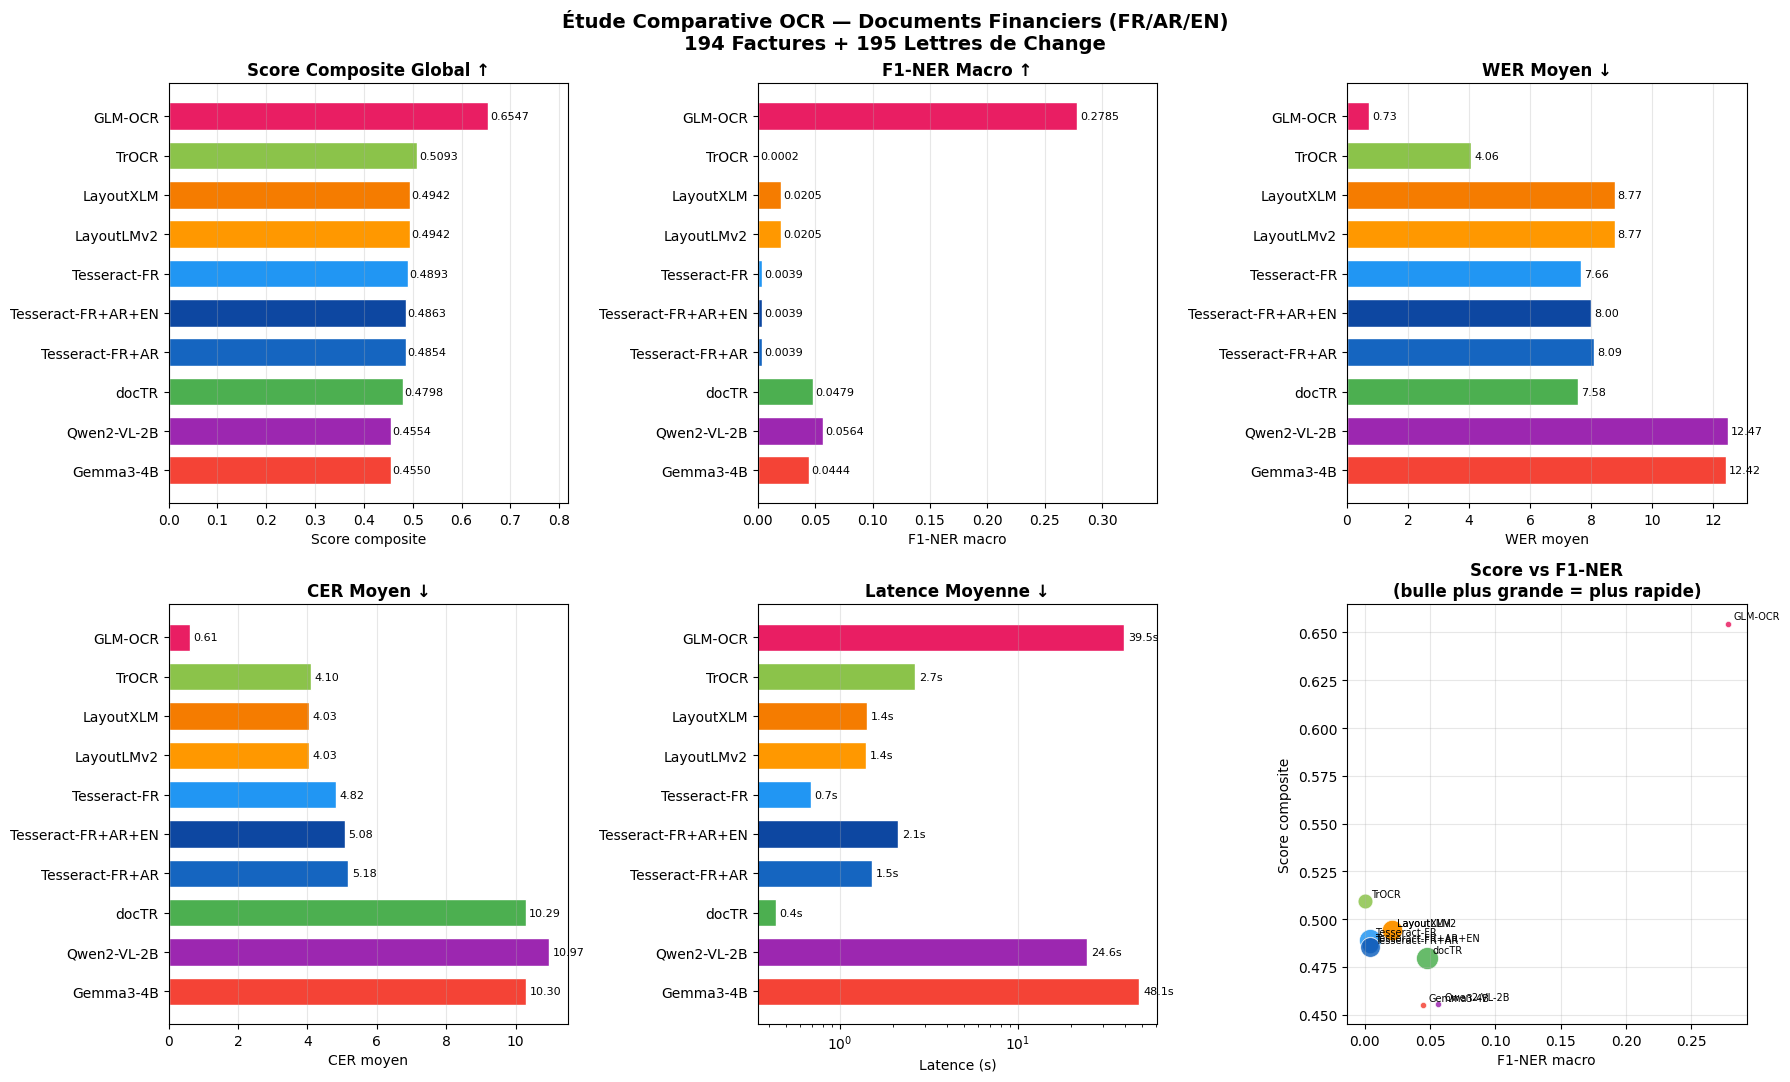

✅ Figure → /kaggle/working/evaluation_finale.png


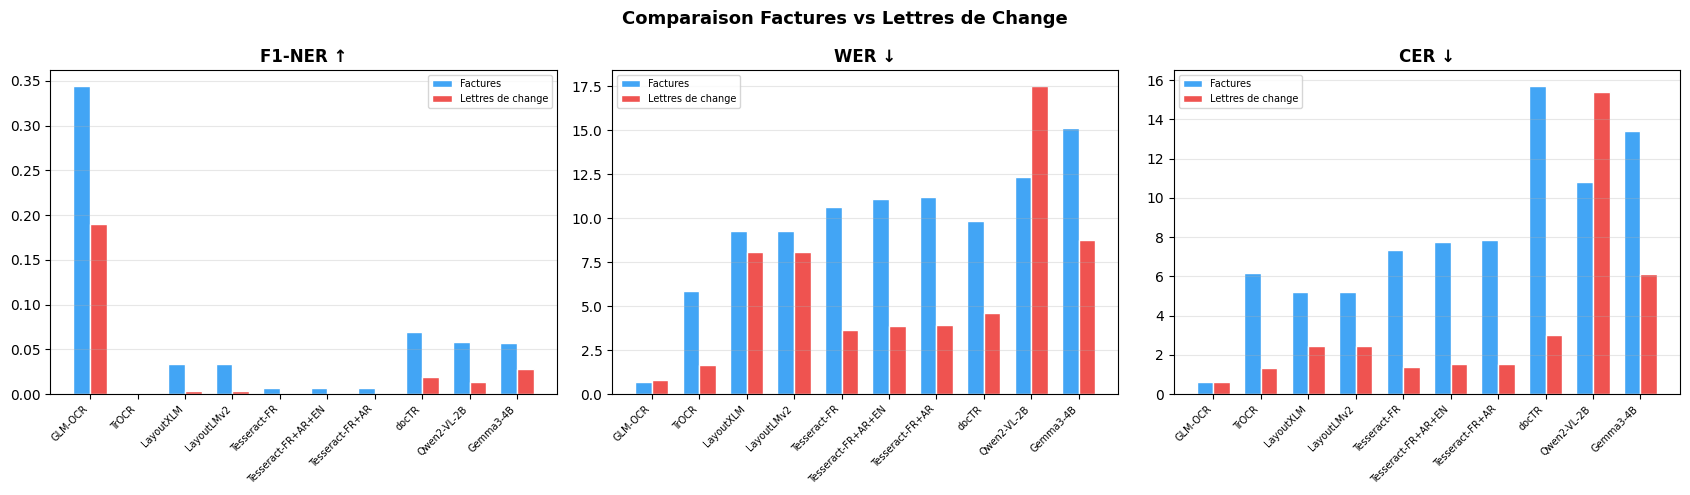

✅ Figure → /kaggle/working/facture_vs_lc.png

FINAL SUMMARY TABLE
            Modele       Groupe    WER↓    CER↓    F1↑  Score↑  Lat(s)↓   N
           GLM-OCR C-MULTIMODAL  0.7317  0.6135 0.2785  0.6547  39.5305 338
             TrOCR        A-OCR  4.0637  4.0991 0.0002  0.5093   2.6502 338
         LayoutXLM        B-DOC  8.7686  4.0334 0.0205  0.4942   1.4133 338
        LayoutLMv2        B-DOC  8.7686  4.0334 0.0205  0.4942   1.4066 338
      Tesseract-FR        A-OCR  7.6639  4.8224 0.0039  0.4893   0.6864 338
Tesseract-FR+AR+EN        A-OCR  8.0016  5.0814 0.0039  0.4863   2.1278 338
   Tesseract-FR+AR        A-OCR  8.0938  5.1778 0.0039  0.4854   1.5099 338
             docTR        A-OCR  7.5849 10.2948 0.0479  0.4798   0.4370 338
       Qwen2-VL-2B C-MULTIMODAL 12.4676 10.9715 0.0564  0.4554  24.5661 200
         Gemma3-4B C-MULTIMODAL 12.4162 10.3025 0.0444  0.4550  48.1024 338

🏆 Best score      : GLM-OCR  (Score=0.6547)
🎯 Best F1-NER     : GLM-OCR (F1=0.2785)
⚡ Fastest    

,Modele,Groupe,WER↓,CER↓,F1↑,Score↑,Lat(s)↓
0,GLM-OCR,C-MULTIMODAL,0.7317,0.6135,0.2785,0.6547,39.5305
8,TrOCR,A-OCR,4.0637,4.0991,0.0002,0.5093,2.6502
3,LayoutXLM,B-DOC,8.7686,4.0334,0.0205,0.4942,1.4133
2,LayoutLMv2,B-DOC,8.7686,4.0334,0.0205,0.4942,1.4066
5,Tesseract-FR,A-OCR,7.6639,4.8224,0.0039,0.4893,0.6864
7,Tesseract-FR+AR+EN,A-OCR,8.0016,5.0814,0.0039,0.4863,2.1278
6,Tesseract-FR+AR,A-OCR,8.0938,5.1778,0.0039,0.4854,1.5099
9,docTR,A-OCR,7.5849,10.2948,0.0479,0.4798,0.4370
4,Qwen2-VL-2B,C-MULTIMODAL,12.4676,10.9715,0.0564,0.4554,24.5661
1,Gemma3-4B,C-MULTIMODAL,12.4162,10.3025,0.0444,0.4550,48.1024


In [ ]:
# ============================================================
# FINAL EVALUATION CELL
# ============================================================
import json, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

JSON_PATH = '/kaggle/input/datasets/<KAGGLE_USER>/ocr-results/ocr_results_all.json'
with open(JSON_PATH, 'r', encoding='utf-8') as f:
    data = json.load(f)

df = pd.DataFrame(data)
print(f"✅ {len(df)} entries | Models: {sorted(df['Modele'].unique())}")

# ── Score composite ───────────────────────────────────────────
df['WER_cap']  = df['WER'].clip(0).apply(lambda x: min(x, 50) / 50)
df['CER_cap']  = df['CER'].clip(0).apply(lambda x: min(x, 50) / 50)
df['F1_norm']  = df['F1_NER_macro'].clip(0, 1).fillna(0)
df['Score']    = df['F1_norm']*0.40 + (1-df['WER_cap'])*0.25 + (1-df['CER_cap'])*0.25 + 0.05

# ── Overall aggregation ───────────────────────────────────────
agg_global = df.groupby(['Modele','Groupe']).agg(
    WER_mean    =('WER',       'mean'),
    CER_mean    =('CER',       'mean'),
    F1_mean     =('F1_norm',   'mean'),
    Score_mean  =('Score',     'mean'),
    Lat_mean    =('Latence_s', 'mean'),
    N           =('Image',     'count')
).round(4).reset_index().sort_values('Score_mean', ascending=False)

print("\n" + "="*70)
print("OVERALL RANKING BY COMPOSITE SCORE")
print("="*70)
print(agg_global.to_string(index=False))

# ── Aggregation per Doc_type ──────────────────────────────────
agg_dt = df.groupby(['Modele','Groupe','Doc_type']).agg(
    WER_mean    =('WER',       'mean'),
    CER_mean    =('CER',       'mean'),
    F1_mean     =('F1_norm',   'mean'),
    Score_mean  =('Score',     'mean'),
    Lat_mean    =('Latence_s', 'mean'),
    N           =('Image',     'count')
).round(4).reset_index()

print("\n" + "="*70)
print("RESULTS PER DOCUMENT TYPE")
print("="*70)
for dtype in ['facture', 'lettre_change']:
    sub = agg_dt[agg_dt['Doc_type']==dtype].sort_values('Score_mean', ascending=False)
    if len(sub):
        print(f"\n  [{dtype.upper()}]")
        print(sub[['Modele','WER_mean','CER_mean','F1_mean','Score_mean','Lat_mean','N']].to_string(index=False))

# ── Visualisations ────────────────────────────────────────────
COLOR_MAP = {
    'Tesseract-FR':'#2196F3', 'Tesseract-FR+AR':'#1565C0', 'Tesseract-FR+AR+EN':'#0D47A1',
    'docTR':'#4CAF50', 'TrOCR':'#8BC34A',
    'LayoutLMv2':'#FF9800', 'LayoutXLM':'#F57C00',
    'Qwen2-VL-2B':'#9C27B0', 'GLM-OCR':'#E91E63', 'Gemma3-4B':'#F44336',
}
models = agg_global['Modele'].tolist()
colors = [COLOR_MAP.get(m,'#607D8B') for m in models]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle('OCR comparative study — financial documents (FR/AR/EN)\n194 invoices + 195 bills of exchange',
             fontsize=14, fontweight='bold')

# 1. Score composite
ax = axes[0,0]
bars = ax.barh(models, agg_global['Score_mean'], color=colors, edgecolor='white', height=0.7)
ax.set_xlabel('Score composite'); ax.set_title('Score Composite Global ↑', fontweight='bold')
ax.set_xlim(0, agg_global['Score_mean'].max()*1.25)
for b,v in zip(bars, agg_global['Score_mean']):
    ax.text(b.get_width()+0.003, b.get_y()+b.get_height()/2, f'{v:.4f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)

# 2. F1-NER
ax = axes[0,1]
bars = ax.barh(models, agg_global['F1_mean'], color=colors, edgecolor='white', height=0.7)
ax.set_xlabel('F1-NER macro'); ax.set_title('F1-NER Macro ↑', fontweight='bold')
ax.set_xlim(0, agg_global['F1_mean'].max()*1.25)
for b,v in zip(bars, agg_global['F1_mean']):
    ax.text(b.get_width()+0.002, b.get_y()+b.get_height()/2, f'{v:.4f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)

# 3. WER moyen
ax = axes[0,2]
bars = ax.barh(models, agg_global['WER_mean'], color=colors, edgecolor='white', height=0.7)
ax.set_xlabel('WER moyen'); ax.set_title('WER Moyen ↓', fontweight='bold')
for b,v in zip(bars, agg_global['WER_mean']):
    ax.text(b.get_width()+0.1, b.get_y()+b.get_height()/2, f'{v:.2f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)

# 4. CER moyen
ax = axes[1,0]
bars = ax.barh(models, agg_global['CER_mean'], color=colors, edgecolor='white', height=0.7)
ax.set_xlabel('CER moyen'); ax.set_title('CER Moyen ↓', fontweight='bold')
for b,v in zip(bars, agg_global['CER_mean']):
    ax.text(b.get_width()+0.1, b.get_y()+b.get_height()/2, f'{v:.2f}', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)

# 5. Latence
ax = axes[1,1]
bars = ax.barh(models, agg_global['Lat_mean'], color=colors, edgecolor='white', height=0.7)
ax.set_xlabel('Latence (s)'); ax.set_title('Latence Moyenne ↓', fontweight='bold')
ax.set_xscale('log')
for b,v in zip(bars, agg_global['Lat_mean']):
    ax.text(b.get_width()*1.05, b.get_y()+b.get_height()/2, f'{v:.1f}s', va='center', fontsize=8)
ax.invert_yaxis(); ax.grid(axis='x', alpha=0.3)

# 6. Scatter Score vs F1
ax = axes[1,2]
for _, row in agg_global.iterrows():
    c = COLOR_MAP.get(row['Modele'], '#607D8B')
    size = max(20, 300 / max(row['Lat_mean'], 0.1))
    size = min(size, 250)
    ax.scatter(row['F1_mean'], row['Score_mean'], s=size, color=c, alpha=0.85, edgecolors='white', lw=0.5)
    ax.annotate(row['Modele'], (row['F1_mean'], row['Score_mean']),
                textcoords='offset points', xytext=(4,3), fontsize=7)
ax.set_xlabel('F1-NER macro'); ax.set_ylabel('Score composite')
ax.set_title('Score vs F1-NER\n(bulle plus grande = plus rapide)', fontweight='bold')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/evaluation_finale.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure → /kaggle/working/evaluation_finale.png")

# ── Invoice vs bill of exchange per metric ────────────────────
fig2, axes2 = plt.subplots(1, 3, figsize=(17, 5))
fig2.suptitle('Invoices vs bills of exchange', fontsize=13, fontweight='bold')
x = np.arange(len(models))
w = 0.35

for ax2, metric, title, up in zip(axes2,
    ['F1_mean','WER_mean','CER_mean'],
    ['F1-NER ↑','WER ↓','CER ↓'],
    [True, False, False]):
    fac = agg_dt[agg_dt['Doc_type']=='facture'].set_index('Modele')[metric]
    lc  = agg_dt[agg_dt['Doc_type']=='lettre_change'].set_index('Modele')[metric]
    fv = [fac.get(m,0) for m in models]
    lv = [lc.get(m,0)  for m in models]
    ax2.bar(x-w/2, fv, w, label='Factures',         color='#42A5F5', edgecolor='white')
    ax2.bar(x+w/2, lv, w, label='Bills of exchange', color='#EF5350', edgecolor='white')
    ax2.set_xticks(x); ax2.set_xticklabels(models, rotation=45, ha='right', fontsize=7)
    ax2.set_title(title, fontweight='bold'); ax2.legend(fontsize=7); ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/facture_vs_lc.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ Figure → /kaggle/working/facture_vs_lc.png")

# ── Tableau final ─────────────────────────────────────────────
print("\n" + "="*70)
print("FINAL SUMMARY TABLE")
print("="*70)
t = agg_global.rename(columns={'WER_mean':'WER↓','CER_mean':'CER↓','F1_mean':'F1↑',
                                 'Score_mean':'Score↑','Lat_mean':'Lat(s)↓'})
print(t[['Modele','Groupe','WER↓','CER↓','F1↑','Score↑','Lat(s)↓','N']].to_string(index=False))

best  = agg_global.iloc[0]
bestF = agg_global.loc[agg_global['F1_mean'].idxmax()]
bestL = agg_global.loc[agg_global['Lat_mean'].idxmin()]
print(f"\n🏆 Best score      : {best['Modele']}  (Score={best['Score_mean']:.4f})")
print(f"🎯 Best F1-NER     : {bestF['Modele']} (F1={bestF['F1_mean']:.4f})")
print(f"⚡ Fastest         : {bestL['Modele']} ({bestL['Lat_mean']:.2f}s/img)")

agg_global.to_csv('/kaggle/working/resultats_finaux_syntese.csv', index=False)
print("\n💾 /kaggle/working/resultats_finaux_syntese.csv")
display(t[['Modele','Groupe','WER↓','CER↓','F1↑','Score↑','Lat(s)↓']].style
    .background_gradient(subset=['Score↑','F1↑'], cmap='Greens')
    .background_gradient(subset=['WER↓','CER↓'], cmap='Reds_r')
    .format(precision=4))